# Evaluación e interpretación

In [1]:
from pathlib import Path
import warnings
import json
import sys
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "funciones"))
import Entrenamiento_red as mod

CARPETA_CURVAS = ROOT / "Curvas"
CARPETA_MODELOS = ROOT / "Resultados_Modelos1"
OUT = ROOT  
SEMILLAS = (1, 2, 3)
CABEZAS = ("lineal", "MLP", "KAN")
N_BOOTSTRAP = 1000
SEMILLA_BOOTSTRAP = 2026
VENTANAS_PICOS = {"Pico_1_MarJun": (13, 36), "Pico_2_SepDic": (49, 72)}

assert (ROOT / "funciones" / "Entrenamiento_red.py").is_file(), "Abre Jupyter en la raíz del proyecto."
assert CARPETA_CURVAS.is_dir() and CARPETA_MODELOS.is_dir()
assert N_BOOTSTRAP >= 1000
print("Carpeta del notebook/proyecto:", ROOT)
print("Los resultados se guardarán directamente en:", OUT)

Carpeta del notebook/proyecto: /Users/estefania/Documents/GitHub/proyecto_final_analiticaDeDatos
Los resultados se guardarán directamente en: /Users/estefania/Documents/GitHub/proyecto_final_analiticaDeDatos


## Evaluación final de los modelos seleccionados

Partición fijada de antemano: entrenamiento **1981–1997** y prueba **1998–2003**, con estaciones distintas. La configuración y la semilla de cada cabeza se fijan solo con la validación cruzada de 5 grupos de estaciones de entrenamiento (notebook 01). Las métricas finales y sus gráficas se calculan en prueba, comparando con el **satélite sin corregir**.

In [2]:
datos = mod.cargar_datos_red(CARPETA_CURVAS, escala='raiz')
meta = datos['meta'].copy().reset_index(drop=True)
ids = meta['curva'].astype(str).to_numpy()
part = meta['particion'].to_numpy()
TRAIN = part == "entrenamiento"
TEST = part == "prueba"

assert TRAIN.sum() > 0 and TEST.sum() > 0 and (TRAIN | TEST).all()

assert meta.loc[TRAIN, "YEAR"].between(1981, 1997).all()
assert meta.loc[TEST, "YEAR"].between(1998, 2003).all()
T = len(meta)
P = np.arange(1, 73)
cols_p = [f'P{k:02d}' for k in P]

def leer_pentadas(nombre):
    d = pd.read_csv(CARPETA_CURVAS / nombre, dtype={'curva': str})
    assert set(cols_p).issubset(d.columns), f'Faltan P01...P72 en {nombre}'
    assert not d['curva'].duplicated().any(), f'Curvas duplicadas en {nombre}'
    return d.set_index('curva').loc[ids, cols_p].to_numpy(float)

Y_crudo = leer_pentadas('curvas_estaciones_72_pentadas.csv')
S_crudo = leer_pentadas('curvas_satelite_72_pentadas.csv')
assert np.isfinite(Y_crudo).all() and np.isfinite(S_crudo).all()
print('Negativos en curvas originales suavizadas (estación/satélite):',
      int((Y_crudo < 0).sum()), int((S_crudo < 0).sum()))
Y = np.maximum(Y_crudo, 0.)
SAT = np.maximum(S_crudo, 0.)

est_tr = set(meta.loc[TRAIN, 'STATION_ID'].astype(str))
est_te = set(meta.loc[TEST, 'STATION_ID'].astype(str))
auditoria = pd.DataFrame({'conjunto':['Entrenamiento','Prueba'],
 'n_curvas':[TRAIN.sum(), TEST.sum()],
 'n_estaciones':[len(est_tr),len(est_te)]})
display(auditoria)
print('Intersecciones estaciones train/test:',len(est_tr & est_te))
print('Años por grupo:',meta.groupby('particion')['YEAR'].agg(['min','max']).to_dict('index'))
if est_tr & est_te: warnings.warn('La prueba temporal incluye estaciones vistas en entrenamiento. NO declarar validación espacial independiente.')


Negativos en curvas originales suavizadas (estación/satélite): 2247 0


,conjunto,n_curvas,n_estaciones
0,Entrenamiento,1958,143
1,Prueba,127,26


Intersecciones estaciones train/test: 0
Años por grupo: {'entrenamiento': {'min': 1981, 'max': 1997}, 'prueba': {'min': 1998, 'max': 2003}}


In [3]:
# Reconstruir predicciones en mm de TODOS los checkpoints, sin promediar semillas.
W_sat, R_sat = mod.matrices_integracion(datos['t'], datos['phi_sat'])
W_est, _ = mod.matrices_integracion(datos['t'], datos['phi_est'])
modelos, estados, predicciones, scores_pred = {}, {}, {}, {}
config_elegida = pd.read_csv(
    ROOT / "Tablas" / "08_red_configuracion_elegida.csv"
).set_index("cabeza")

for cabeza in CABEZAS:
    for semilla in SEMILLAS:
        ruta = CARPETA_MODELOS / f'red_{cabeza}_semilla{semilla:04d}.pt'
        if not ruta.is_file():
            print('Checkpoint no encontrado:',ruta.name)
            continue
        ck = torch.load(ruta,map_location='cpu',weights_only=False)  # solo checkpoints propios/confiables
        assert int(ck['q']) == int(config_elegida.loc[cabeza, 'q'])
        assert int(ck['M']) == int(config_elegida.loc[cabeza, 'M'])
        assert np.isclose(float(ck['lambda']),float(config_elegida.loc[cabeza, 'lambda']))
        escala = ck.get('escala','raiz')
        d = datos if escala=='raiz' else mod.cargar_datos_red(CARPETA_CURVAS, escala=escala)
        modelo = mod.crear_modelo(cabeza, W_sat, R_sat, int(ck['q']), int(ck['M']))
        modelo.load_state_dict(ck['estado'])
        modelo.eval()
        cov = (d['cov'] - ck['media_covariables']) / ck['desviacion_covariables']
        with torch.no_grad():
            s = modelo(torch.as_tensor(d['c_sat'],dtype=torch.float64),
                       torch.as_tensor(cov,dtype=torch.float64)).cpu().numpy()
        coef = ck['media_coeficientes'] + s @ ck['base_coeficientes']
        pred, recortes = mod.reconstruir_mm(coef,d['phi_est'][d['filas_pentadas']],escala)
        assert pred.shape == Y.shape and np.isfinite(pred).all() and np.min(pred)>=0
        nombre = f'{cabeza}_s{semilla}'
        modelos[nombre] = modelo; estados[nombre] = ck
        predicciones[nombre] = pred; scores_pred[nombre] = s
        print(f'{nombre:12s} q={ck["q"]}, M={ck["M"]}, '
              f'lambda={ck["lambda"]:g}, valores recortados={recortes:.2f}%')
assert predicciones, 'No se encontraron checkpoints: revisa Resultados_Modelos1/'

print('Modelos cargados:', len(predicciones))
display(pd.DataFrame([{'modelo':n,'min_pred_mm':float(p[TEST].min()),'max_pred_mm':float(p[TEST].max()),'media_pred_mm':float(p[TEST].mean())} for n,p in predicciones.items()]).round(3))


lineal_s1    q=8, M=5, lambda=10, valores recortados=0.00%
lineal_s2    q=8, M=5, lambda=10, valores recortados=0.00%
lineal_s3    q=8, M=5, lambda=10, valores recortados=0.02%
MLP_s1       q=8, M=5, lambda=100, valores recortados=0.02%
MLP_s2       q=8, M=5, lambda=100, valores recortados=0.00%
MLP_s3       q=8, M=5, lambda=100, valores recortados=0.02%
KAN_s1       q=8, M=5, lambda=10, valores recortados=0.03%
KAN_s2       q=8, M=5, lambda=10, valores recortados=0.04%
KAN_s3       q=8, M=5, lambda=10, valores recortados=0.03%
Modelos cargados: 9


,modelo,min_pred_mm,max_pred_mm,media_pred_mm
0,lineal_s1,0.368,82.463,21.338
1,lineal_s2,0.272,80.054,20.094
2,lineal_s3,0.053,80.735,20.165
3,MLP_s1,0.448,144.945,23.471
4,MLP_s2,1.261,82.101,23.576
5,MLP_s3,1.477,166.576,27.498
6,KAN_s1,0.000,148.064,22.543
7,KAN_s2,0.000,190.420,25.250
8,KAN_s3,0.000,181.842,21.729


In [4]:
# Selección de la semilla con la validación cruzada del notebook 01, antes de mirar métricas en prueba.
# Cada curva de entrenamiento tiene la predicción del modelo que no vio su grupo de estaciones.
vc = np.load(CARPETA_MODELOS / 'predicciones_vc.npz', allow_pickle=True)
assert (vc['curva'] == ids).all(), 'Las curvas no coinciden con la exportación de R.'

def recm_vc(nombre):
    cabeza, semilla = nombre.rsplit('_s', 1)
    c_vc = vc[f'{cabeza}_semilla{int(semilla):04d}'][TRAIN]
    assert np.isfinite(c_vc).all()
    pred_vc = mod.reconstruir_mm(c_vc, datos['phi_est'][datos['filas_pentadas']], str(vc['escala']))[0]
    delta = pred_vc - Y[TRAIN]
    return float(np.mean(np.sqrt(np.mean(delta**2, axis=1))))

REFS = {}
for cabeza in CABEZAS:
    candidatos = [nombre for nombre in predicciones if nombre.startswith(cabeza + '_')]
    if candidatos:
        REFS[cabeza] = min(candidatos, key=recm_vc)
assert 'KAN' in REFS, 'Falta al menos un checkpoint KAN.'
KAN_REF = REFS['KAN']
print('RECM de validación cruzada por semilla:', {n: round(recm_vc(n), 3) for n in predicciones})
print('Modelos fijados por validación cruzada:', REFS)

RECM de validación cruzada por semilla: {'lineal_s1': 10.258, 'lineal_s2': 10.289, 'lineal_s3': 10.378, 'MLP_s1': 9.091, 'MLP_s2': 9.363, 'MLP_s3': 9.486, 'KAN_s1': 9.173, 'KAN_s2': 9.095, 'KAN_s3': 9.113}
Modelos fijados por validación cruzada: {'lineal': 'lineal_s1', 'MLP': 'MLP_s1', 'KAN': 'KAN_s2'}


In [5]:
# Referencias de la evaluación: curva suavizada de la estación (Y) y del satélite sin corregir (SAT), recortadas en 0
EVAL = TEST
print('Prueba:', int(TEST.sum()), 'curvas')

Prueba: 127 curvas


## Las cuatro métricas obligatorias en prueba

Comparación de la KAN, los modelos de referencia y el satélite sin corregir frente a la **curva suavizada de la estación** (recortada en 0): **L² relativo**, **KGE 2009**, **sesgo del acumulado anual (%)** y **error de fecha de ambos picos**. Como métrica auxiliar se conserva RECM. Se usan todas las curvas de prueba. Las ventanas de pico son las definidas previamente y las fechas se representan mediante péntadas de cinco días.

In [6]:
def metricas_por_curva(obs, pred):
    obs = np.asarray(obs, dtype=float)
    pred = np.asarray(pred, dtype=float)
    assert obs.shape == pred.shape and obs.ndim == 2 and obs.shape[1] == 72
    assert np.isfinite(obs).all() and np.isfinite(pred).all()
    err = pred - obs
    norma_error = np.sqrt(np.trapezoid(err**2, x=P, axis=1))
    norma_obs = np.sqrt(np.trapezoid(obs**2, x=P, axis=1))
    l2_rel = norma_error / np.where(norma_obs > 1e-12, norma_obs, np.nan)
    rmse = np.sqrt(np.mean(err**2, axis=1))
    om, pm = obs.mean(axis=1), pred.mean(axis=1)
    os, ps = obs.std(axis=1), pred.std(axis=1)
    r = np.mean((obs-om[:,None])*(pred-pm[:,None]), axis=1) / np.where(os*ps > 1e-12, os*ps, np.nan)
    alpha = ps / np.where(os > 1e-12, os, np.nan)
    beta = pm / np.where(np.abs(om) > 1e-12, om, np.nan)
    kge = 1 - np.sqrt((r-1)**2 + (alpha-1)**2 + (beta-1)**2)
    acum_obs, acum_pred = obs.sum(axis=1), pred.sum(axis=1)
    sesgo = 100*(acum_pred-acum_obs)/np.where(acum_obs > 1e-12, acum_obs, np.nan)
    tabla = pd.DataFrame({'L2_relativo':l2_rel, 'RECM_mm':rmse, 'KGE':kge,
                         'sesgo_anual_pct':sesgo, 'acum_obs_mm':acum_obs, 'acum_pred_mm':acum_pred})
    for etiqueta, (inicio, fin) in VENTANAS_PICOS.items():
        sl = slice(inicio-1, fin)
        po = np.argmax(obs[:, sl], axis=1) + inicio
        pp = np.argmax(pred[:, sl], axis=1) + inicio
        tabla[f'error_{etiqueta}_dias'] = np.abs(pp-po)*5
        tabla[f'pico_obs_{etiqueta}'] = po
        tabla[f'pico_pred_{etiqueta}'] = pp
    tabla['error_dos_picos_dias'] = tabla[[f'error_{k}_dias' for k in VENTANAS_PICOS]].mean(axis=1)
    return tabla

metricas = {}

for nombre, pred in [('Satelite', SAT), *[(nombre, predicciones[nombre]) for nombre in REFS.values()]]:
    tabla = metricas_por_curva(Y[EVAL], pred[EVAL])
    tabla.insert(0, 'modelo', nombre)
    tabla.insert(1, 'curva', ids[EVAL])
    tabla.insert(2, 'particion', part[EVAL])
    tabla.insert(3, 'STATION_ID', meta.loc[EVAL,'STATION_ID'].astype(str).to_numpy())
    tabla.insert(4, 'YEAR', meta.loc[EVAL,'YEAR'].to_numpy())
    metricas[nombre] = tabla
metricas_curva = pd.concat(metricas.values(), ignore_index=True)
campos = ['L2_relativo','RECM_mm','KGE','sesgo_anual_pct',
          'error_Pico_1_MarJun_dias','error_Pico_2_SepDic_dias','error_dos_picos_dias']
resumen = metricas_curva.groupby('modelo')[campos].mean().round(4)
display(resumen)


,L2_relativo,RECM_mm,KGE,sesgo_anual_pct,error_Pico_1_MarJun_dias,error_Pico_2_SepDic_dias,error_dos_picos_dias
modelo,,,,,,,
KAN_s2,0.3629,10.9466,0.4933,-6.6119,20.0394,9.2913,14.6654
MLP_s1,0.3559,11.2297,0.5099,-9.4877,21.1417,10.7087,15.9252
Satelite,0.4453,13.9368,0.4006,2.3334,16.5354,29.3701,22.9528
lineal_s1,0.3926,13.0752,0.4562,-14.2841,19.4882,9.2913,14.3898


## IC bootstrap del 95 % por estaciones

Se remuestrean **estaciones completas** (no péntadas individuales) con reemplazo, conservando juntos los años de una misma estación. Se calculan ≥1000 réplicas, IC percentiles del 95 % y diferencias pareadas frente al satélite sin corregir. Los IC condicionan en los checkpoints fijados: no incluyen incertidumbre por reentrenamiento.

,modelo,metrica,n_validos,estimacion,ic95_inf,ic95_sup,diferencia_vs_satelite,dif_ic95_inf,dif_ic95_sup
0,Satelite,L2_relativo,127,0.4453,0.3937,0.5064,0.0000,0.0000,0.0000
2,Satelite,KGE,127,0.4006,0.3230,0.4691,0.0000,0.0000,0.0000
3,Satelite,sesgo_anual_pct,127,2.3334,-11.2059,16.8802,0.0000,0.0000,0.0000
4,Satelite,error_Pico_1_MarJun_dias,127,16.5354,14.0068,19.0803,0.0000,0.0000,0.0000
5,Satelite,error_Pico_2_SepDic_dias,127,29.3701,27.1000,31.4890,0.0000,0.0000,0.0000
6,Satelite,error_dos_picos_dias,127,22.9528,21.2889,24.6902,0.0000,0.0000,0.0000
7,lineal_s1,L2_relativo,127,0.3926,0.3542,0.4310,-0.0528,-0.0996,-0.0121
9,lineal_s1,KGE,127,0.4562,0.3885,0.5237,0.0556,0.0005,0.1191
10,lineal_s1,sesgo_anual_pct,127,-14.2841,-24.1920,-3.3679,-16.6175,-21.0486,-12.8096
11,lineal_s1,error_Pico_1_MarJun_dias,127,19.4882,16.7969,22.0630,2.9528,1.0244,4.7700


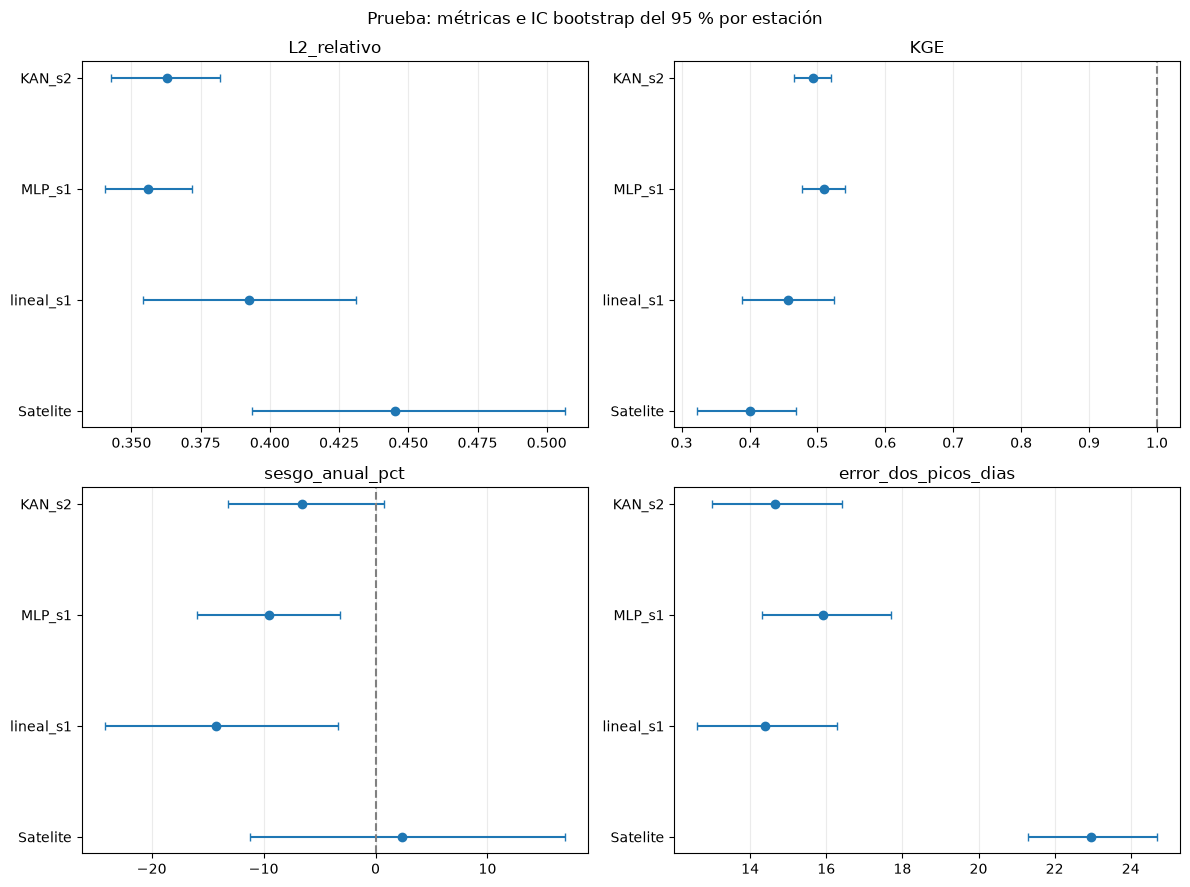

In [7]:
rng = np.random.default_rng(SEMILLA_BOOTSTRAP)
grupos = meta.loc[EVAL, 'STATION_ID'].astype(str).to_numpy()
estaciones = np.unique(grupos)
indices_por_est = {e:np.flatnonzero(grupos == e) for e in estaciones}
replicas = []
for b in range(N_BOOTSTRAP):
    muestra = rng.choice(estaciones, len(estaciones), replace=True)
    replicas.append(np.concatenate([indices_por_est[e] for e in muestra]))
assert len(replicas) >= 1000 and all(ix.max() < EVAL.sum() for ix in replicas)

met_test = {n:t[campos].reset_index(drop=True) for n,t in metricas.items()}
registros = []
for nombre, t in met_test.items():
    for campo in campos:
        vals = t[campo].to_numpy(float)
        base = met_test['Satelite'][campo].to_numpy(float)
        boot = np.array([np.nanmean(vals[ix]) for ix in replicas])
        dif = np.array([np.nanmean(vals[ix]-base[ix]) for ix in replicas])
        registros.append({'modelo':nombre, 'metrica':campo, 'n_validos':int(np.isfinite(vals).sum()),
                          'estimacion':np.nanmean(vals), 'ic95_inf':np.nanquantile(boot,.025),
                          'ic95_sup':np.nanquantile(boot,.975),
                          'diferencia_vs_satelite':np.nanmean(vals-base),
                          'dif_ic95_inf':np.nanquantile(dif,.025), 'dif_ic95_sup':np.nanquantile(dif,.975)})
boot_res = pd.DataFrame(registros)
display(boot_res[boot_res.metrica.isin(['L2_relativo','KGE','sesgo_anual_pct','error_dos_picos_dias',
                                     'error_Pico_1_MarJun_dias','error_Pico_2_SepDic_dias'])].round(4))
fig, axs = plt.subplots(2,2,figsize=(12,9))
for ax,campo in zip(axs.flat,['L2_relativo','KGE','sesgo_anual_pct','error_dos_picos_dias']):
    sub = boot_res[boot_res.metrica.eq(campo)].reset_index(drop=True)
    yy = np.arange(len(sub))
    ax.errorbar(sub.estimacion,yy,
                xerr=[sub.estimacion-sub.ic95_inf,sub.ic95_sup-sub.estimacion],fmt='o',capsize=3)
    ax.set_yticks(yy,sub.modelo)
    ax.set_title(campo)
    ax.grid(axis='x',alpha=.25)
    if campo == 'sesgo_anual_pct':ax.axvline(0,color='gray',ls='--')
    if campo == 'KGE':ax.axvline(1,color='gray',ls='--')
fig.suptitle('Prueba: métricas e IC bootstrap del 95 % por estación')
fig.tight_layout();plt.show()

## Curva de la estación, satélite sin corregir y KAN en prueba

Se presentan los casos de mayor mejora, mayor deterioro, máxima precipitación y comportamiento intermedio, y se grafica el error medio por péntada. 

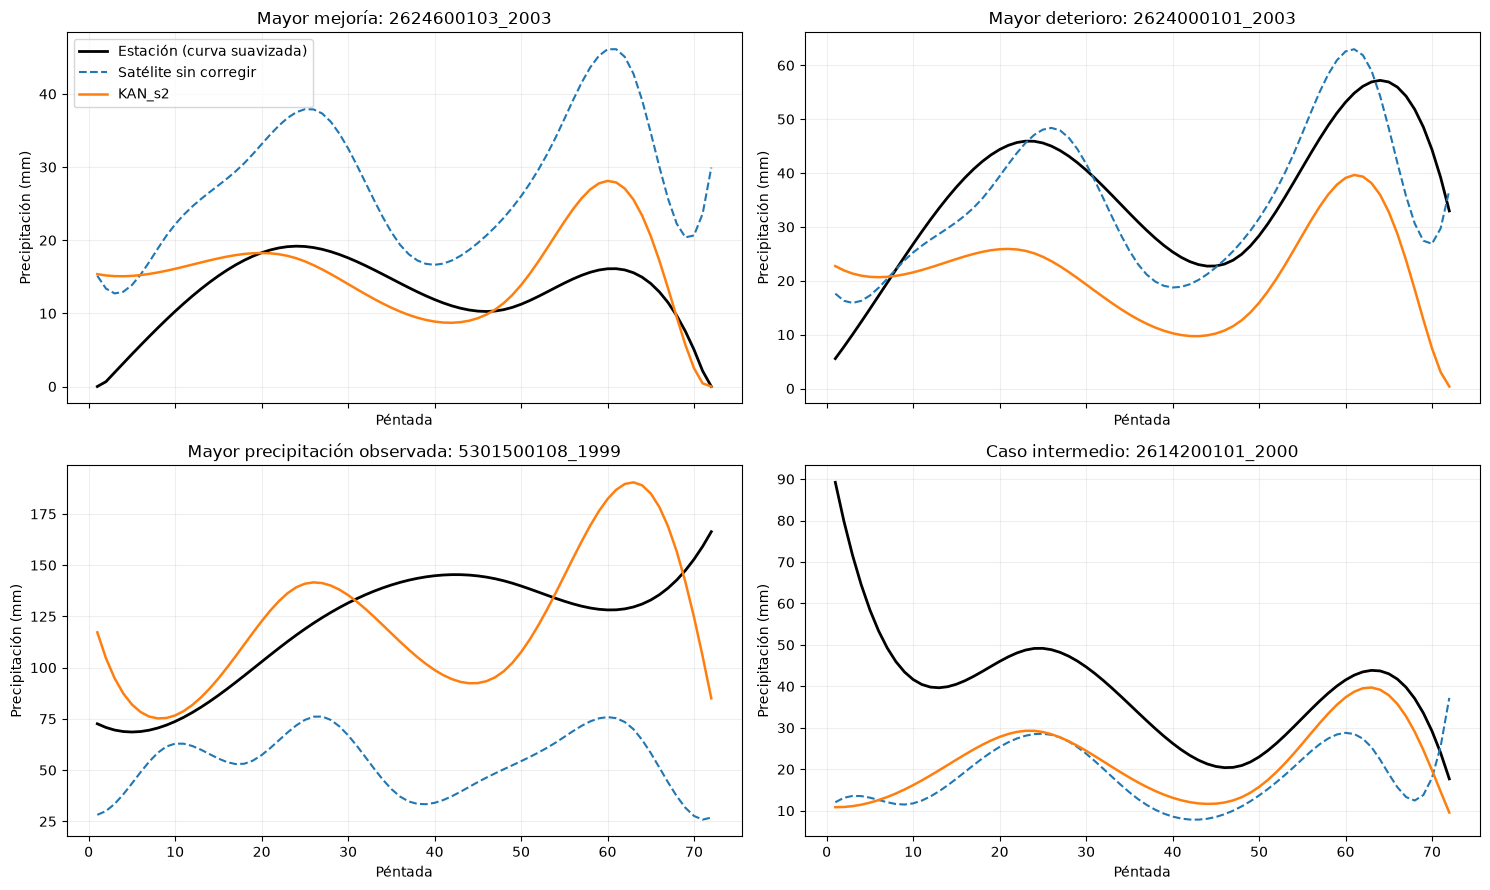

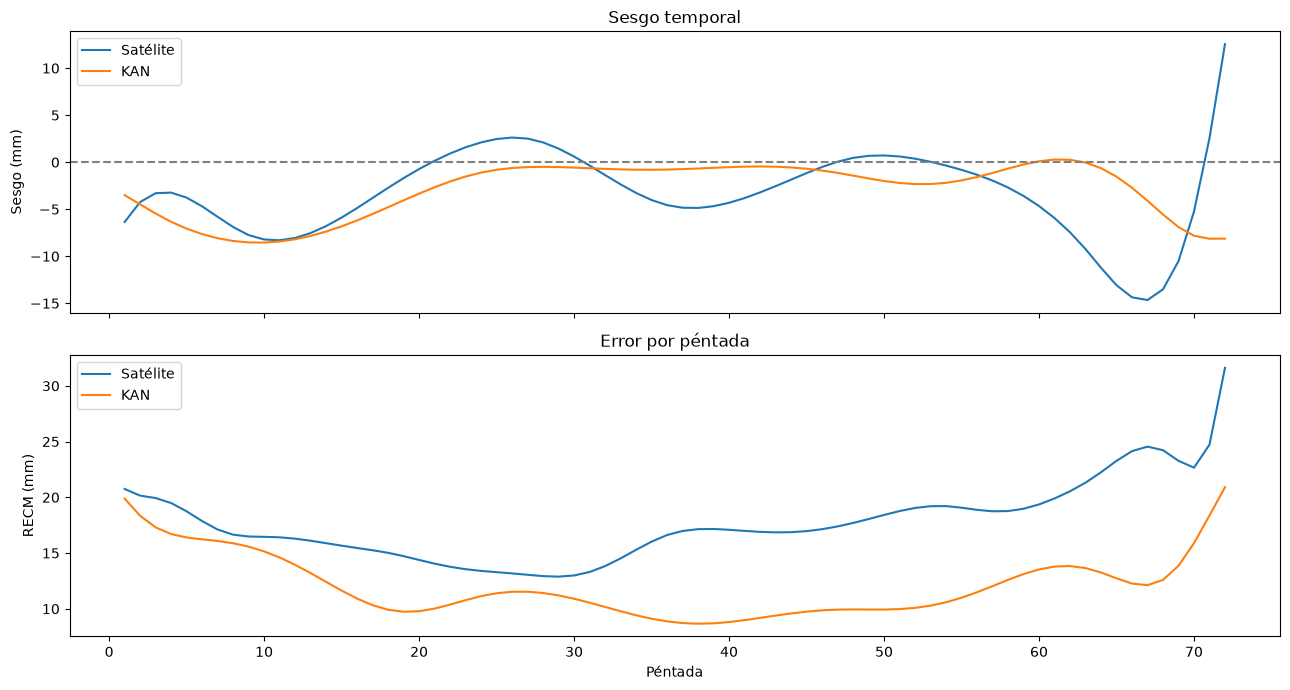

In [8]:
indices = np.flatnonzero(EVAL)
obs_test = Y[EVAL]
sat_test = SAT[EVAL]
kan_test = predicciones[KAN_REF][EVAL]
met_kan = metricas_por_curva(obs_test,kan_test)
met_sat = metricas_por_curva(obs_test,sat_test)
mejora = met_sat['L2_relativo'].to_numpy() - met_kan['L2_relativo'].to_numpy()
pos = [int(np.argmax(mejora)), int(np.argmin(mejora)),
       int(np.argmax(obs_test.sum(axis=1))), int(np.argmin(np.abs(mejora-np.median(mejora))))]
casos = indices[pos]
etiquetas = ['Mayor mejoría','Mayor deterioro','Mayor precipitación observada','Caso intermedio']
fig,axs = plt.subplots(2,2,figsize=(15,9),sharex=True)
for ax,i,etiqueta in zip(axs.flat,casos,etiquetas):
    ax.plot(P,Y[i],label='Estación (curva suavizada)',color='black',linewidth=2)
    ax.plot(P,SAT[i],label='Satélite sin corregir',linestyle='--')
    ax.plot(P,predicciones[KAN_REF][i],label=KAN_REF,linewidth=1.8)
    ax.set_title(f'{etiqueta}: {ids[i]}')
    ax.set(xlabel='Péntada',ylabel='Precipitación (mm)');ax.grid(alpha=.2)
axs[0,0].legend();fig.tight_layout()
plt.show()

fig,axs=plt.subplots(2,1,figsize=(13,7),sharex=True)
for nombre,pred in [('Satélite',SAT),('KAN',predicciones[KAN_REF])]:
    error=pred[EVAL]-Y[EVAL]
    axs[0].plot(P,error.mean(axis=0),label=nombre)
    axs[1].plot(P,np.sqrt(np.mean(error**2,axis=0)),label=nombre)
axs[0].axhline(0,color='gray',ls='--');axs[0].set(ylabel='Sesgo (mm)',title='Sesgo temporal')
axs[1].set(ylabel='RECM (mm)',xlabel='Péntada',title='Error por péntada')
axs[0].legend();axs[1].legend();fig.tight_layout()
plt.show()

## Resultados según fase ENSO

Las fases se toman de `data/enso_evaluacion.csv`, clasificado con el ONI mensual por ventanas trimestrales móviles. **Fuente del índice ONI:** NOAA Climate Prediction Center (CPC), https://www.cpc.ncep.noaa.gov/products/analysis_monitoring/ensostuff/ONI_v5.php. El RECM por fase se calcula sobre el tramo temporal de cada fase.

Columnas ENSO: ['YEAR', 'mes_central', 'ventana', 'ONI', 'fase_enso']


,modelo,fase,n_segmentos,n_pentadas,RECM_medio,sesgo_pct_medio
0,KAN_s2,El Niño,63,1650,9.130,12.846
1,KAN_s2,La Niña,86,3880,12.008,-8.779
2,KAN_s2,Neutral,104,3614,7.768,-4.753
3,Satelite,El Niño,63,1650,10.656,15.419
4,Satelite,La Niña,86,3880,15.452,-7.323
5,Satelite,Neutral,104,3614,10.880,11.940


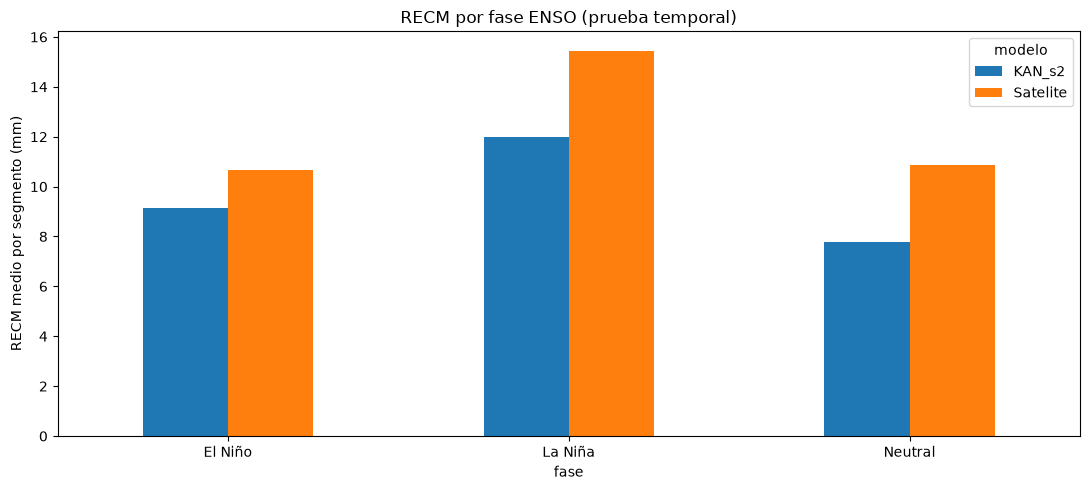

In [9]:
ruta_enso=ROOT/'data'/'enso_evaluacion.csv'
if ruta_enso.exists():
    enso=pd.read_csv(ruta_enso)
    print('Columnas ENSO:',enso.columns.to_list())
    fase_dict={(int(r.YEAR),int(r.mes_central)):str(r.fase_enso) for r in enso.itertuples()}
    # Centros aproximados de las 72 péntadas repartidas en 360 días
    fechas=pd.to_datetime('2001-01-01')+pd.to_timedelta((P-.5)*5,unit='D')
    meses=fechas.month.to_numpy()
    rows=[]
    for nombre,pred in [('Satelite',SAT),(KAN_REF,predicciones[KAN_REF])]:
        for i in np.flatnonzero(EVAL):
            fases=np.asarray([fase_dict.get((int(meta.YEAR.iloc[i]),int(m)),'Sin dato') for m in meses])
            for fase in np.unique(fases):
                ix=fases==fase
                if fase=='Sin dato':continue
                dif=pred[i,ix]-Y[i,ix]
                so=Y[i,ix].sum()
                rows.append({'modelo':nombre,'curva':ids[i],'estacion':str(meta.STATION_ID.iloc[i]),
                             'YEAR':int(meta.YEAR.iloc[i]),'fase':fase,'n_pentadas':int(ix.sum()),
                             'RECM_mm':float(np.sqrt(np.mean(dif**2))),
                             'sesgo_pct':float(100*dif.sum()/so) if so>0 else np.nan})
    ensodf=pd.DataFrame(rows)
    enso_res=ensodf.groupby(['modelo','fase']).agg(n_segmentos=('curva','size'),
                  n_pentadas=('n_pentadas','sum'),RECM_medio=('RECM_mm','mean'),
                  sesgo_pct_medio=('sesgo_pct','mean')).reset_index()
    display(enso_res.round(3))
    piv=enso_res.pivot(index='fase',columns='modelo',values='RECM_medio')
    piv.plot(kind='bar',figsize=(11,5),rot=0,title='RECM por fase ENSO (prueba temporal)')
    plt.ylabel('RECM medio por segmento (mm)');plt.tight_layout()
    plt.show()
else:
    print('No se encuentra data/enso_evaluacion.csv; omito ENSO sin inventar etiquetas.')


## Comprobación FPCA: error irrecuperable del decodificador y puntajes

Para evitar confundir la falla de la cabeza con un límite de la FPCA, proyectamos la **curva real transformada** sobre la base FPCA guardada (solo para diagnóstico). Es un **oráculo**, no un modelo predictivo, por lo que nunca debe reportarse como competidor. La figura de puntajes ayuda a detectar colapso hacia la media. La FPCA usada por las tres cabezas debe proceder únicamente de entrenamiento.

RECM del piso de reconstrucción FPCA (ORÁCULO, no predictor): 3.4635042710081763
RECM KAN: 10.946649368518937


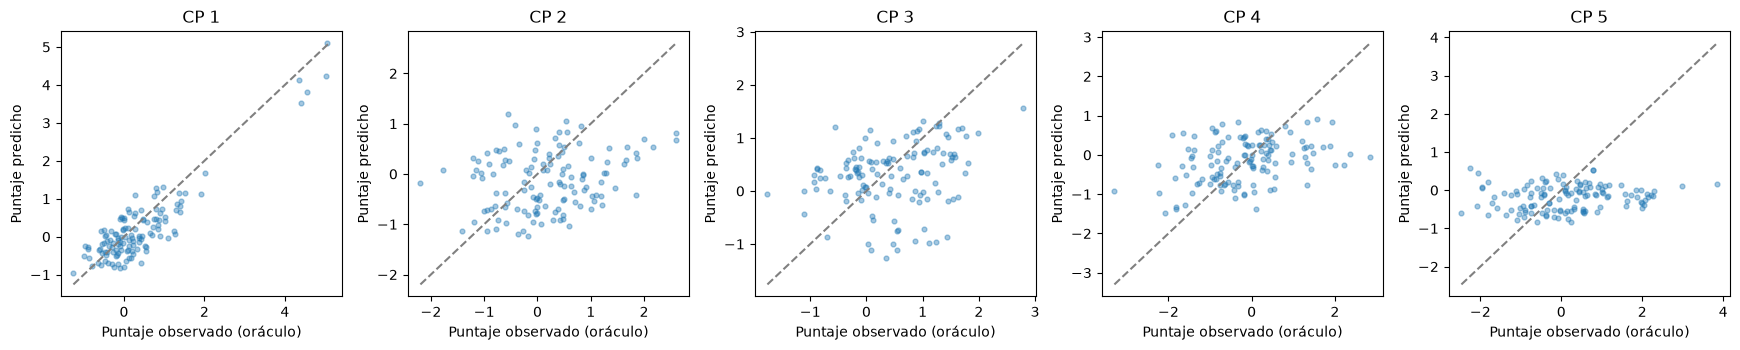

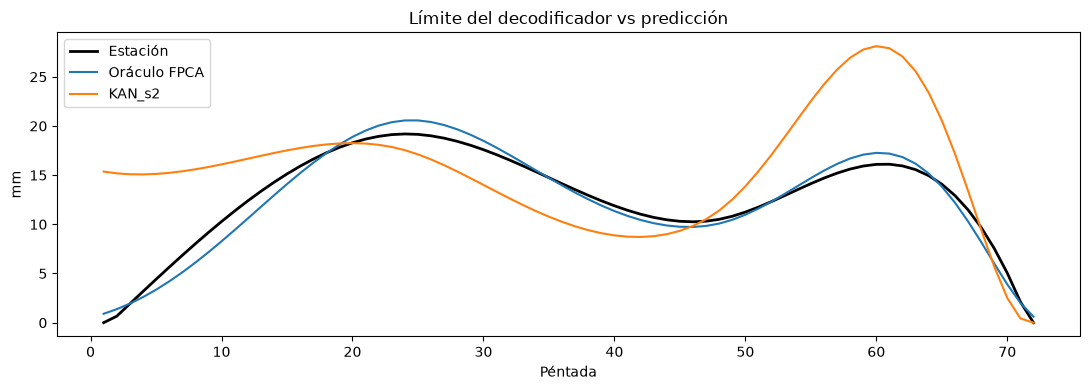

In [10]:
ck=estados[KAN_REF]
M=int(ck['M'])
# La FPCA en el checkpoint está expresada en la malla de las 72 péntadas, en la escala transformada
mu=np.asarray(ck['media_fpca'],float)
psi=np.asarray(ck['base_fpca'],float)  # M x 72, incluye escala de puntajes
phi_e=datos['phi_est'][datos['filas_pentadas']]
curvas_transformadas=datos['c_est'] @ phi_e.T
# puntajes de mínimos cuadrados en la base REAL escalada, sin presuponer ortonormalidad después del escalado
puntajes_obs=np.linalg.lstsq(psi.T,(curvas_transformadas-mu).T,rcond=None)[0].T
recon_transformada=mu+puntajes_obs@psi
escala=ck.get('escala','raiz')
recon_oraculo=mod.TRANSFORMACIONES[escala][1](np.maximum(recon_transformada,0.0))
print('RECM del piso de reconstrucción FPCA (ORÁCULO, no predictor):',
      float(np.mean(metricas_por_curva(Y,recon_oraculo)['RECM_mm'].to_numpy()[TEST])))
print('RECM KAN:',float(np.mean(metricas_por_curva(Y,predicciones[KAN_REF])['RECM_mm'].to_numpy()[TEST])))
fig,axs=plt.subplots(1,M,figsize=(3.5*M,3.6))
axs=np.atleast_1d(axs)
for j,ax in enumerate(axs):
    ax.scatter(puntajes_obs[TEST,j],scores_pred[KAN_REF][TEST,j],alpha=.4,s=12)
    lo=min(puntajes_obs[TEST,j].min(),scores_pred[KAN_REF][TEST,j].min())
    hi=max(puntajes_obs[TEST,j].max(),scores_pred[KAN_REF][TEST,j].max())
    ax.plot([lo,hi],[lo,hi],ls='--',c='gray')
    ax.set(xlabel='Puntaje observado (oráculo)',ylabel='Puntaje predicho',title=f'CP {j+1}')
fig.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(P,Y[casos[0]],label='Estación',lw=2,color='black')
ax.plot(P,recon_oraculo[casos[0]],label='Oráculo FPCA')
ax.plot(P,predicciones[KAN_REF][casos[0]],label=KAN_REF)
ax.legend();ax.set(xlabel='Péntada',ylabel='mm',title='Límite del decodificador vs predicción');plt.tight_layout()
plt.show()


## Pesos funcionales aprendidos \(w_k(t)\)

Se grafican los pesos funcionales de cada neurona, resaltando las dos ventanas estacionales. Los signos de los pesos no indican precipitación negativa ni prueban causalidad. 

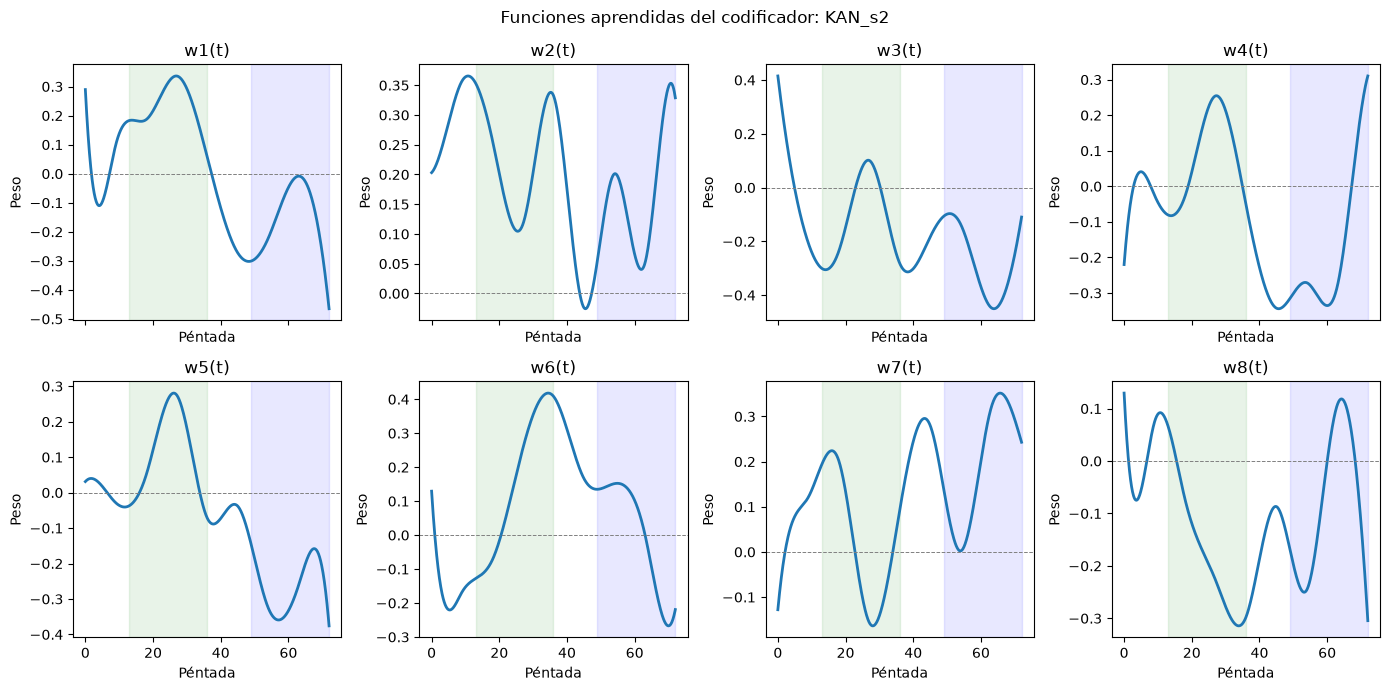

,neurona,energia_L2,rugosidad
0,1,3.0147,0.0172
1,2,3.7481,0.0072
2,3,4.2069,0.0050
3,4,3.1568,0.0068
4,5,2.4326,0.0060
5,6,3.3072,0.0082
6,7,2.5763,0.0048
7,8,2.0064,0.0098


In [11]:
modelo_kan=modelos[KAN_REF]
q=int(ck['q'])
w=modelo_kan.codificador.funciones_pesos(datos['phi_sat'])
fig,axs=plt.subplots(2,4,figsize=(14,7),sharex=True)
for j,ax in enumerate(axs.flat):
    if j>=q:ax.axis('off');continue
    ax.plot(datos['t'],w[:,j],lw=2)
    ax.axhline(0,ls='--',c='gray',lw=.7)
    ax.axvspan(13,36,alpha=.09,color='green');ax.axvspan(49,72,alpha=.09,color='blue')
    ax.set(title=f'w{j+1}(t)',xlabel='Péntada',ylabel='Peso')
fig.suptitle(f'Funciones aprendidas del codificador: {KAN_REF}')
fig.tight_layout();plt.show()
A=modelo_kan.codificador.A.detach().numpy()
energia=np.einsum('ik,kl,il->i',A,W_sat,A)
rugosidad=np.einsum('ik,kl,il->i',A,R_sat,A)
df_w=pd.DataFrame({'neurona':np.arange(1,q+1),'energia_L2':energia,'rugosidad':rugosidad})
display(df_w.round(4))


## Activaciones KAN, cobertura de la calibración y contribución real

,entrada,fuera_menos1_mas1_train_pct,fuera_menos1_mas1_test_pct,min_norm_test,max_norm_test
0,z1,0.51,0.00,0.11,0.82
1,z2,88.36,86.61,0.69,3.52
2,z3,0.15,0.00,-0.38,0.96
3,z4,2.66,2.36,-0.28,1.02
4,z5,4.65,5.51,-0.16,1.04
5,z6,0.66,0.00,-0.89,0.45
6,z7,17.77,17.32,-1.18,-0.07
7,z8,9.55,12.60,-0.24,1.10
8,Altitud,0.00,0.00,-0.93,0.28
9,ONI,0.00,18.11,-1.18,0.37


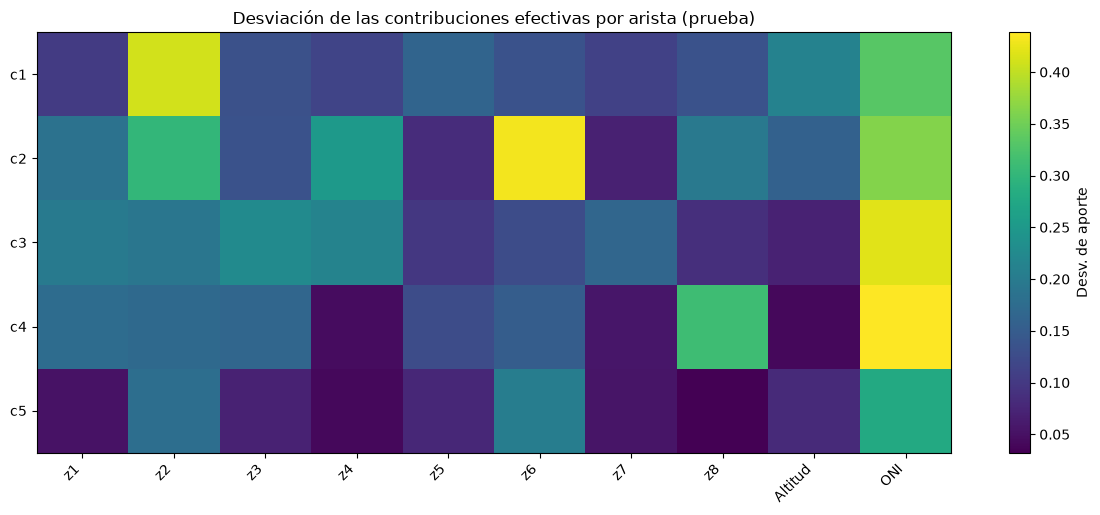

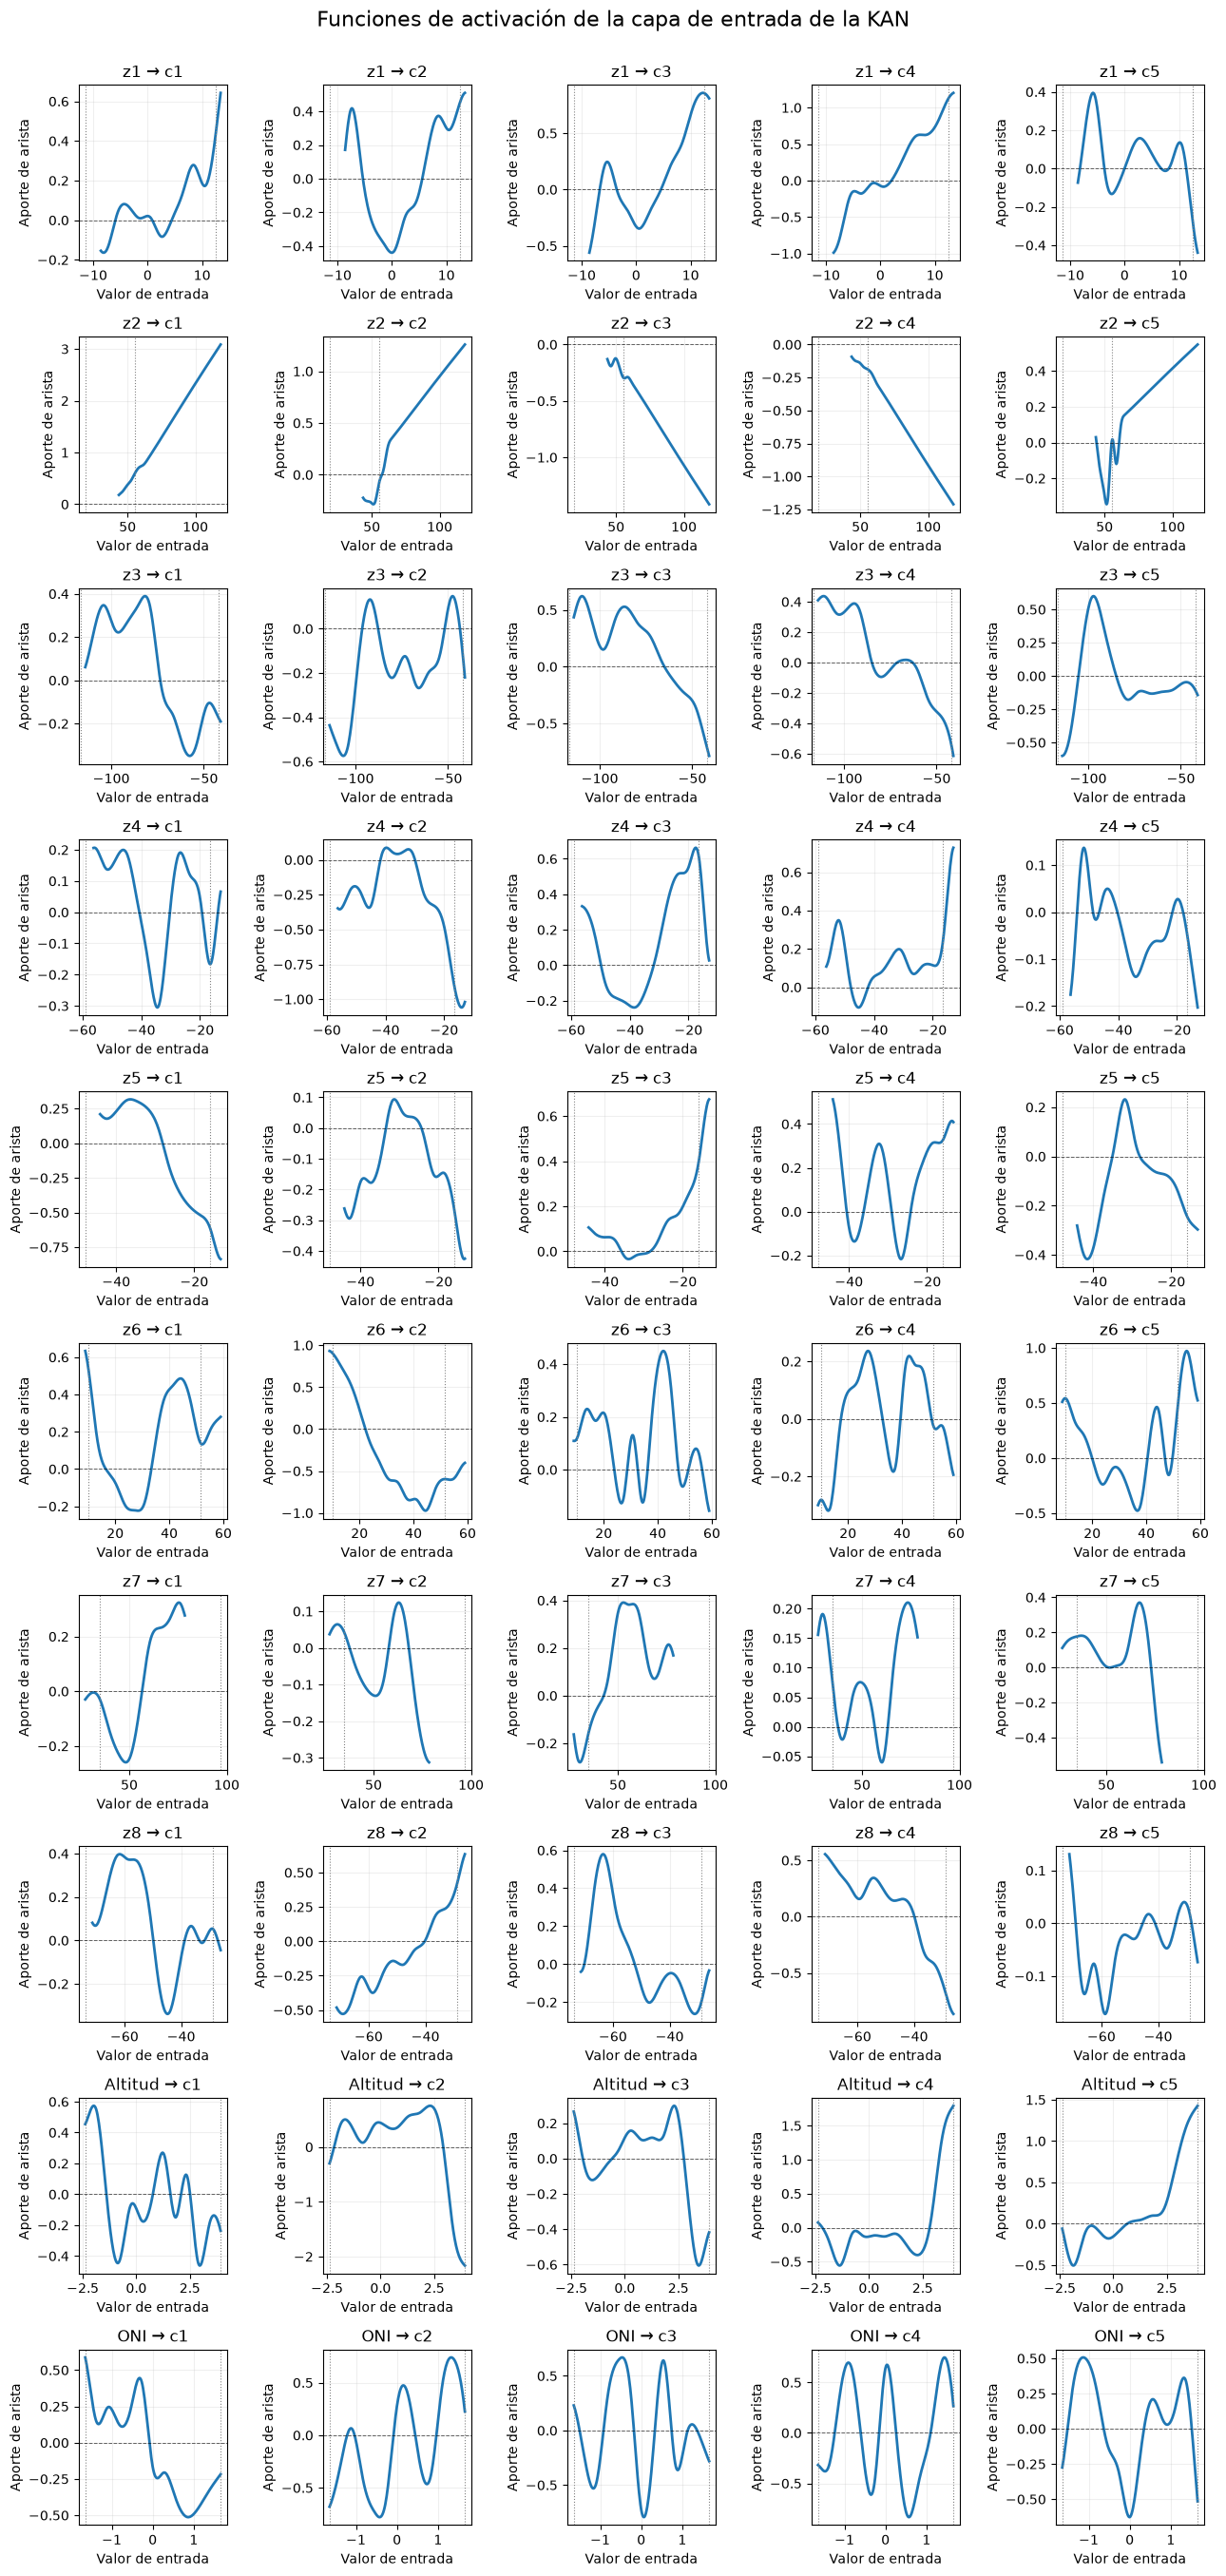

Funciones de activación graficadas: 10 entradas × 5 salidas = 50 funciones


In [12]:
cov = (datos['cov'] - ck['media_covariables']) / ck['desviacion_covariables']

with torch.no_grad():
    H = modelo_kan.codificador(
        torch.as_tensor(datos['c_sat'], dtype=torch.float64),
        torch.as_tensor(cov, dtype=torch.float64)
    ).numpy()

cap = modelo_kan.cabeza.capas[0]
labels = [f'z{k+1}' for k in range(q)] + ['Altitud', 'ONI']
n_entradas = H.shape[1]
n_ocultas = cap.salidas
# Salidas de la capa: nodos ocultos (H) o, sin capa oculta, puntajes FPCA (c)
salida_kan = 'H' if len(modelo_kan.cabeza.capas) > 1 else 'c'

normalizado = (H - cap.centro.detach().numpy()) / cap.escala.detach().numpy()

cobertura = pd.DataFrame({
    'entrada': labels,
    'fuera_menos1_mas1_train_pct': 100 * np.mean(np.abs(normalizado[TRAIN]) > 1, axis=0),
    'fuera_menos1_mas1_test_pct': 100 * np.mean(np.abs(normalizado[TEST]) > 1, axis=0),
    'min_norm_test': normalizado[TEST].min(axis=0),
    'max_norm_test': normalizado[TEST].max(axis=0)
})

display(cobertura.round(2))

contrib = np.zeros((n_ocultas, n_entradas, int(TEST.sum())))

for j in range(n_ocultas):
    for k in range(n_entradas):
        with torch.no_grad():
            contrib[j, k] = cap.arista(j, k, torch.as_tensor(H[TEST, k], dtype=torch.float64)).numpy()

importancia = contrib.std(axis=2)

fig, ax = plt.subplots(figsize=(12, 3 + n_ocultas * 0.45))
im = ax.imshow(importancia, aspect='auto', cmap='viridis')
ax.set_xticks(range(len(labels)), labels, rotation=45, ha='right')
ax.set_yticks(range(n_ocultas), [f'{salida_kan}{j+1}' for j in range(n_ocultas)])
ax.set_title('Desviación de las contribuciones efectivas por arista (prueba)')
fig.colorbar(im, ax=ax, label='Desv. de aporte')
fig.tight_layout()
plt.show()

importancia_train = np.zeros_like(importancia)

for j in range(n_ocultas):
    for k in range(n_entradas):
        with torch.no_grad():
            v = cap.arista(j, k, torch.as_tensor(H[TRAIN, k], dtype=torch.float64)).numpy()
        importancia_train[j, k] = np.std(v)

fig, axs = plt.subplots(n_entradas, n_ocultas, figsize=(13, 2.7 * n_entradas), squeeze=False)

for k in range(n_entradas):
    x = H[TRAIN, k]
    lo = float(np.min(x))
    hi = float(np.max(x))
    if hi <= lo:
        hi = lo + 1e-6
    grid = np.linspace(lo, hi, 200)
    centro = float(cap.centro[k].detach().item())
    escala = float(cap.escala[k].detach().item())
    limite_inferior = centro - escala
    limite_superior = centro + escala

    for j in range(n_ocultas):
        ax = axs[k, j]
        with torch.no_grad():
            v = cap.arista(j, k, torch.as_tensor(grid, dtype=torch.float64)).numpy()

        ax.plot(grid, v, linewidth=2, label='Activación KAN')
        ax.axvline(limite_inferior, color='gray', linestyle=':', linewidth=0.8)
        ax.axvline(limite_superior, color='gray', linestyle=':', linewidth=0.8)
        ax.axhline(0, color='black', linestyle='--', linewidth=0.7, alpha=0.6)
        ax.set_title(f'{labels[k]} → {salida_kan}{j+1}')
        ax.set_xlabel('Valor de entrada')
        ax.set_ylabel('Aporte de arista')
        ax.grid(alpha=0.2)

fig.suptitle('Funciones de activación de la capa de entrada de la KAN', fontsize=16, y=1.002)
fig.tight_layout()
plt.show()

print(f'Funciones de activación graficadas: {n_entradas} entradas × {n_ocultas} salidas = {n_entradas * n_ocultas} funciones')

## Contraste de la KAN con los coeficientes de la cabeza lineal

La KAN tiene contribuciones dependientes de la entrada; la lineal tiene una matriz fija \(B\). Para comparar de forma descriptiva, mostramos las magnitudes de las contribuciones \(h_k B_{mk}\) para la lineal en el mismo conjunto temporal y, por separado, las de la KAN. 

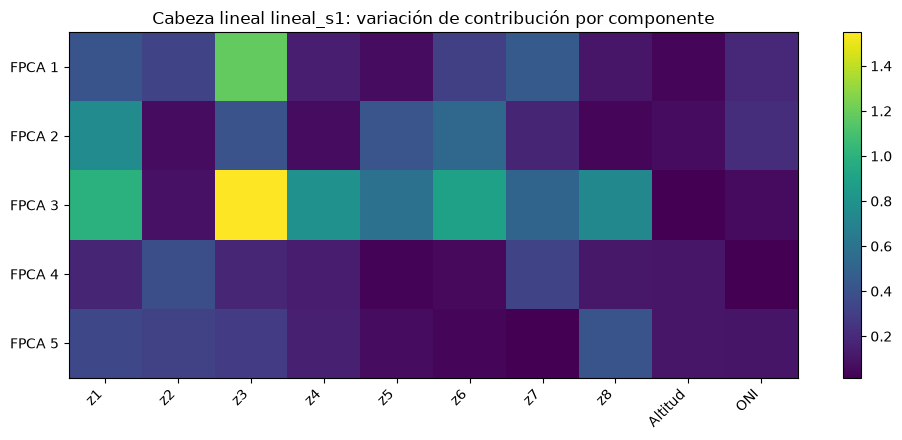

Matriz de coeficientes lineales B (filas FPCA, columnas entradas):


,z1,z2,z3,z4,z5,z6,z7,z8,Altitud,ONI
0,0.114,-0.123,0.198,-0.040,-0.036,-0.090,0.196,-0.033,-0.046,-0.216
1,0.208,0.025,0.069,-0.019,-0.233,0.155,0.075,-0.011,-0.088,0.241
2,0.275,-0.035,0.261,0.220,0.325,-0.264,-0.222,-0.223,0.028,0.067
3,-0.048,-0.143,0.030,-0.039,0.017,0.017,0.145,-0.035,0.143,0.022
4,-0.096,0.119,0.048,-0.042,0.038,-0.012,0.007,-0.128,0.142,-0.116


In [13]:
if 'lineal' in REFS:
    nom=REFS['lineal']; lineal=modelos[nom]; cl=estados[nom]
    cv=(datos['cov']-cl['media_covariables'])/cl['desviacion_covariables']
    with torch.no_grad():
        h=lineal.codificador(torch.as_tensor(datos['c_sat'],dtype=torch.float64),
                             torch.as_tensor(cv,dtype=torch.float64)).numpy()
    B=lineal.cabeza.capa.weight.detach().numpy() # [M,q+2]
    aportes=h[TEST,:,None]*B.T[None,:,:] # [casos, q+2, M]
    fig,ax=plt.subplots(figsize=(10,4.5))
    v=np.std(aportes,axis=0).T
    img=ax.imshow(v,aspect='auto',cmap='viridis')
    ax.set_yticks(range(v.shape[0]),[f'FPCA {k+1}' for k in range(v.shape[0])])
    ax.set_xticks(range(v.shape[1]),[f'z{k+1}' for k in range(v.shape[1]-2)]+['Altitud','ONI'],rotation=45,ha='right')
    ax.set_title(f'Cabeza lineal {nom}: variación de contribución por componente')
    fig.colorbar(img,ax=ax);fig.tight_layout();plt.show()
    print('Matriz de coeficientes lineales B (filas FPCA, columnas entradas):')
    display(pd.DataFrame(B,columns=[f'z{k+1}' for k in range(B.shape[1]-2)]+['Altitud','ONI']).round(3))


## Ajuste simbólico de una activación KAN 

Arista: ONI -> c2 
R2 en puntos alternos no usados en ajuste: 0.443522
u=(x-centro)/escala; centro= 0.005692329492812065 escala= 1.6484781696361295
phi_aprox(u)= (-0.2003285) + (+0.4440976)*u^1 + (+0.3642043)*u^2 + (+0.07311531)*u^3


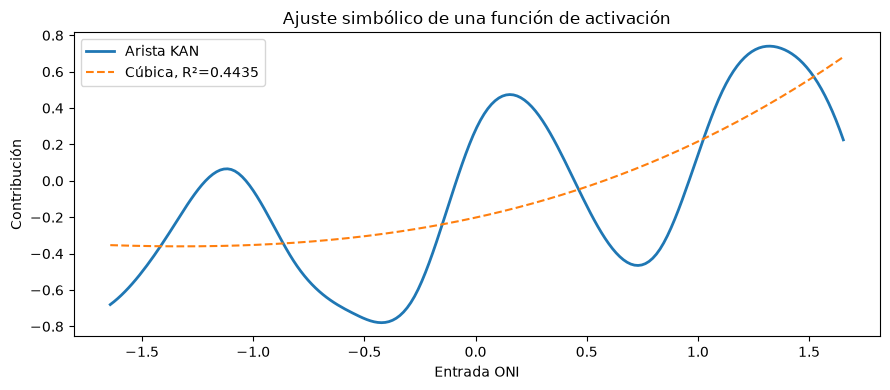

In [14]:
variabilidad_train=np.zeros_like(importancia)
for j in range(n_ocultas):
    for k in range(H.shape[1]):
        with torch.no_grad():
            v=cap.arista(j,k,torch.as_tensor(H[TRAIN,k],dtype=torch.float64)).numpy()
        variabilidad_train[j,k]=np.std(v)
j,k=np.unravel_index(np.argmax(variabilidad_train),variabilidad_train.shape)
lo,hi=np.quantile(H[TRAIN,k],[.01,.99]);hi=max(hi,lo+1e-6)
rejilla=torch.linspace(float(lo),float(hi),201,dtype=torch.float64)
coef,aprox,r2=mod.ajustar_simbolica(cap,int(j),int(k),rejilla)
with torch.no_grad(): original=cap.arista(int(j),int(k),rejilla).numpy()
u=((rejilla-cap.centro[k])/cap.escala[k]).numpy()
coef=coef.detach().numpy()
formula=' + '.join(f'({v:+.7g})*u^{p}' if p else f'({v:+.7g})' for p,v in enumerate(coef))
print('Arista:',labels[k],f'-> {salida_kan}{j+1}', '\nR2 en puntos alternos no usados en ajuste:',round(float(r2),6))
print('u=(x-centro)/escala; centro=',float(cap.centro[k]),'escala=',float(cap.escala[k]))
print('phi_aprox(u)=',formula)
fig,ax=plt.subplots(figsize=(9,4))
ax.plot(rejilla.numpy(),original,label='Arista KAN',lw=2)
ax.plot(rejilla.numpy(),aprox.detach().numpy(),ls='--',label=f'Cúbica, R²={r2:.4f}')
ax.set(xlabel=f'Entrada {labels[k]}',ylabel='Contribución',title='Ajuste simbólico de una función de activación')
ax.legend();fig.tight_layout();plt.show()


,YEAR,ONI_promedio,ONI_min,ONI_max,ONI_rango,ONI_desv,Meses_ONI_positivo,Meses_ONI_negativo
17,1998,0.042,-1.5,2.2,3.7,1.304,5,7
18,1999,-1.058,-1.5,-0.8,0.7,0.261,0,12
19,2000,-0.775,-1.5,-0.4,1.1,0.347,0,12
20,2001,-0.283,-0.8,0.0,0.8,0.217,0,11
21,2002,0.533,-0.1,1.2,1.3,0.427,11,1
22,2003,0.233,-0.2,0.9,1.1,0.303,9,2


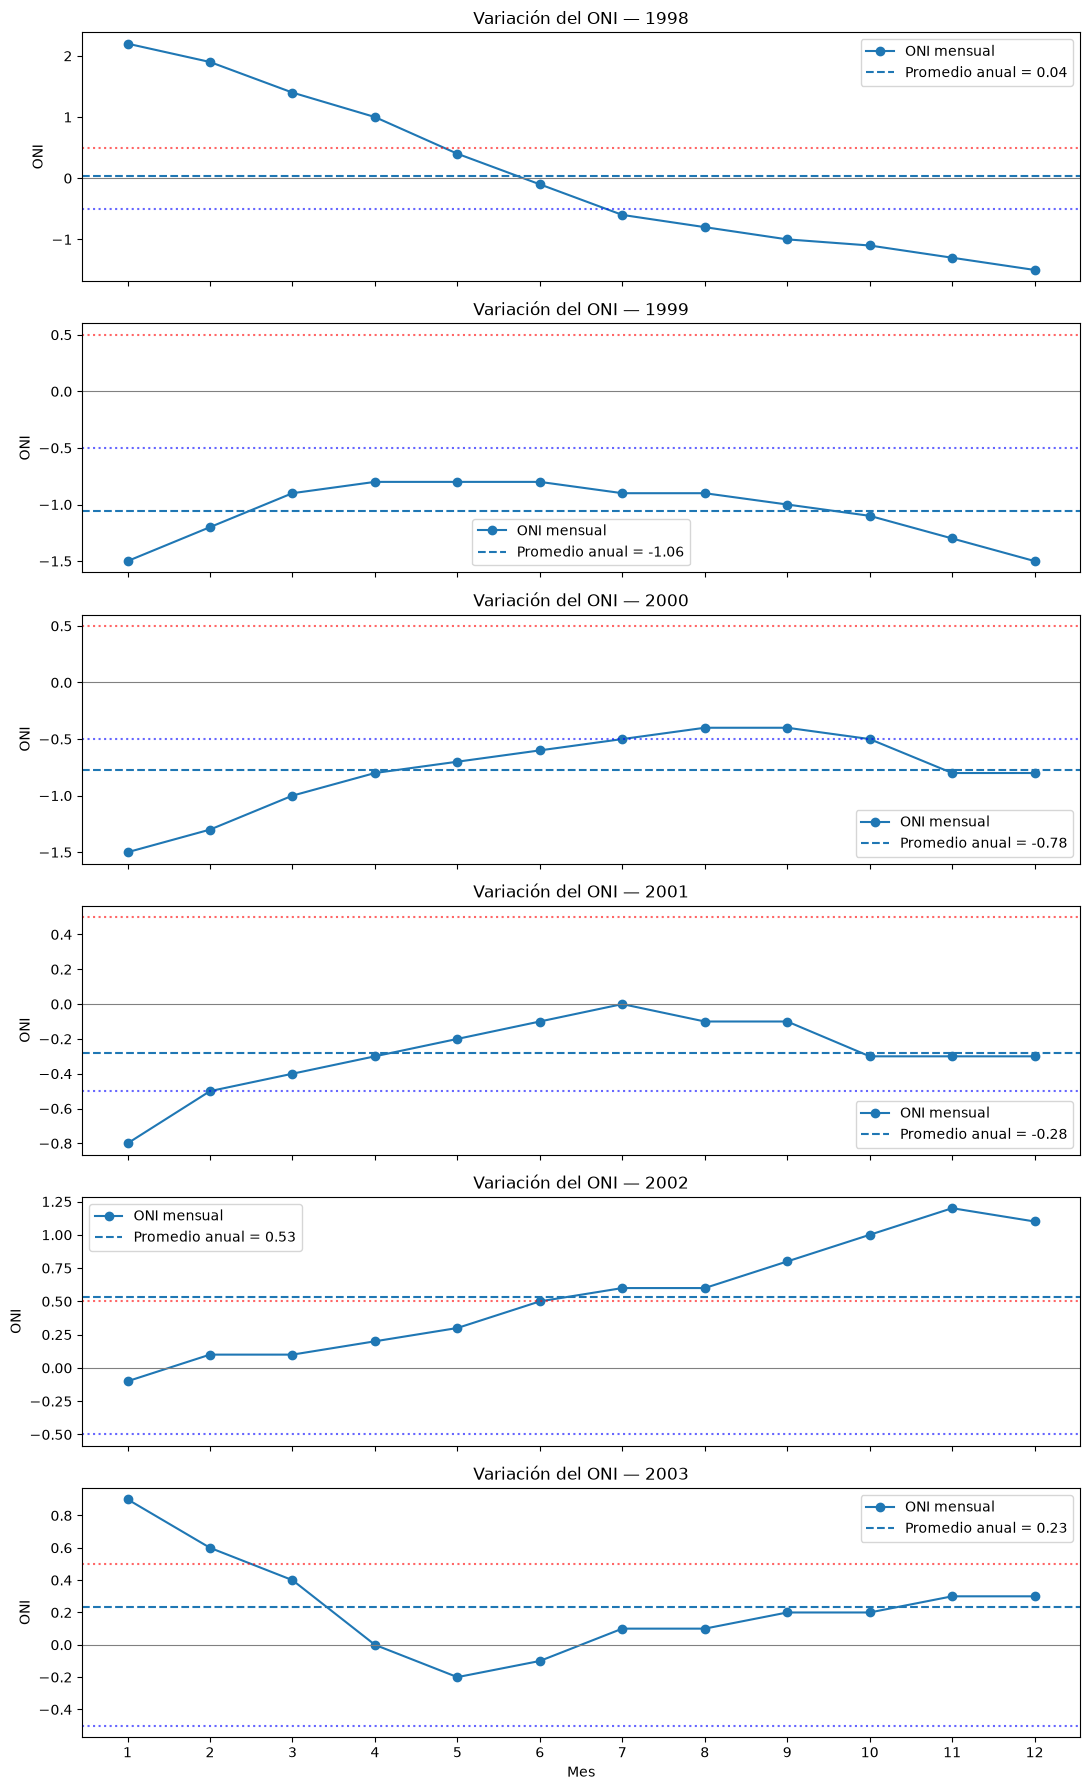

Rango temporal medio del ONI: 1.396
Años con ONI de ambos signos: 9


In [15]:
enso_diag = pd.read_csv(ROOT / "data" / "enso_evaluacion.csv")

oni_mensual = (
    enso_diag.pivot_table(
        index="YEAR",
        columns="mes_central",
        values="ONI",
        aggfunc="mean"
    )
    .reindex(columns=range(1, 13))
    .sort_index()
)

assert oni_mensual.notna().all().all(), "Hay meses ONI faltantes."

resumen_oni = pd.DataFrame({
    "YEAR": oni_mensual.index,
    "ONI_promedio": oni_mensual.mean(axis=1).values,
    "ONI_min": oni_mensual.min(axis=1).values,
    "ONI_max": oni_mensual.max(axis=1).values,
    "ONI_rango": (
        oni_mensual.max(axis=1) -
        oni_mensual.min(axis=1)
    ).values,
    "ONI_desv": oni_mensual.std(axis=1).values,
    "Meses_ONI_positivo": (oni_mensual > 0).sum(axis=1).values,
    "Meses_ONI_negativo": (oni_mensual < 0).sum(axis=1).values
})

resumen_oni_prueba = resumen_oni[resumen_oni['YEAR'].between(1998,2003)].copy()
display(resumen_oni_prueba.round(3))

# Elegir años representativos según las anomalías.
anios_ejemplo = list(resumen_oni_prueba['YEAR'].astype(int))

fig, axs = plt.subplots(
    len(anios_ejemplo), 1,
    figsize=(11, 3 * len(anios_ejemplo)),
    sharex=True
)
axs = np.atleast_1d(axs)

for ax, anio in zip(axs, anios_ejemplo):
    valores = oni_mensual.loc[anio].values
    promedio = valores.mean()

    ax.plot(range(1, 13), valores, marker="o", label="ONI mensual")
    ax.axhline(promedio, linestyle="--",
               label=f"Promedio anual = {promedio:.2f}")
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.axhline(0.5, color="red", linestyle=":", alpha=0.6)
    ax.axhline(-0.5, color="blue", linestyle=":", alpha=0.6)
    ax.set_title(f"Variación del ONI — {anio}")
    ax.set_ylabel("ONI")
    ax.legend()

axs[-1].set_xticks(range(1, 13))
axs[-1].set_xlabel("Mes")
plt.tight_layout()
plt.show()

print("Rango temporal medio del ONI:",
      round(resumen_oni.ONI_rango.mean(), 3))
print("Años con ONI de ambos signos:",
      int(((oni_mensual.min(axis=1) < 0) &
           (oni_mensual.max(axis=1) > 0)).sum()))


Diferencia máxima entre ONI anual original y tabla mensual: 3.3306690738754696e-15


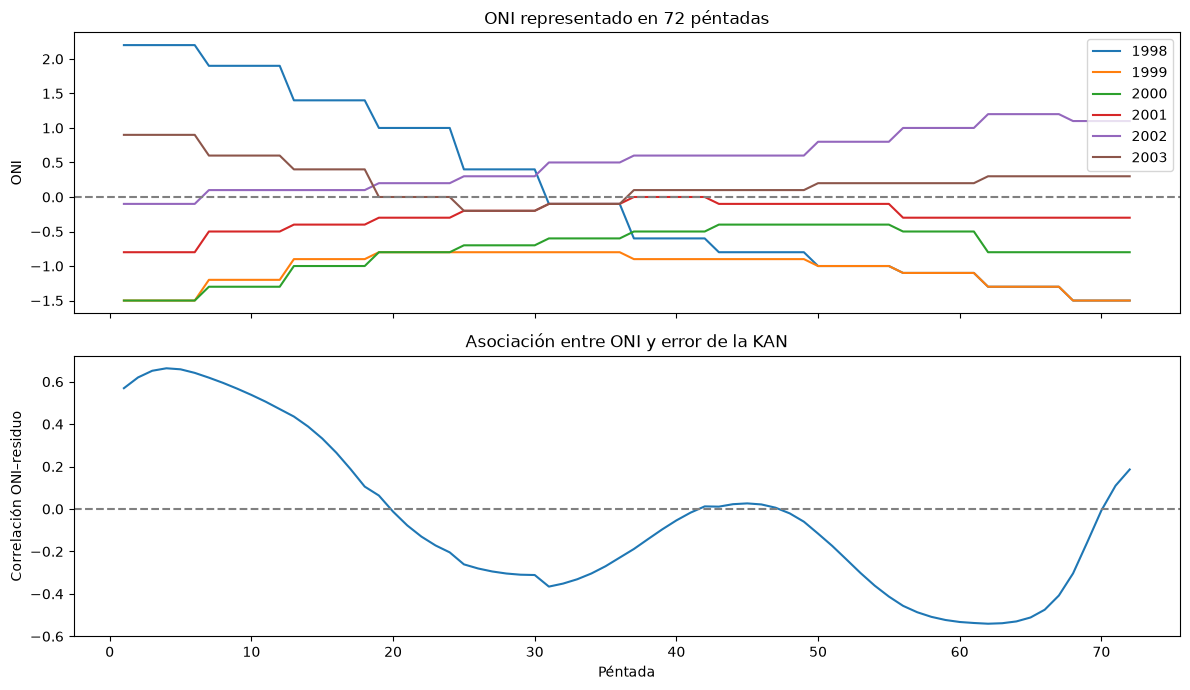

,Pentada,Mes,Correlacion_ONI_residuo
0,1,1,0.569
1,2,1,0.620
2,3,1,0.651
3,4,1,0.663
4,5,1,0.658
...,...,...,...
67,68,12,-0.304
68,69,12,-0.157
69,70,12,-0.007
70,71,12,0.110


In [16]:
fechas_p = pd.Timestamp("2001-01-01") + pd.to_timedelta((P - 0.5) * 5, unit="D")
meses_p = fechas_p.month.to_numpy()

ONI_funcional = np.full((len(meta), len(P)), np.nan)

for i, anio in enumerate(meta["YEAR"].astype(int)):
    if anio in oni_mensual.index:
        ONI_funcional[i] = oni_mensual.loc[anio, meses_p].to_numpy()

assert np.isfinite(ONI_funcional).all()

oni_actual = meta["oni_promedio"].to_numpy(float)
oni_tabla = meta["YEAR"].map(oni_mensual.mean(axis=1)).to_numpy(float)

print("Diferencia máxima entre ONI anual original y tabla mensual:", np.max(np.abs(oni_actual - oni_tabla)))

residuo_kan = predicciones[KAN_REF] - Y

correlaciones = []
for j, pentada in enumerate(P):
    x = ONI_funcional[EVAL, j]
    e = residuo_kan[EVAL, j]
    r = np.corrcoef(x, e)[0, 1] if np.std(x) > 1e-10 and np.std(e) > 1e-10 else np.nan
    correlaciones.append(r)

fig, axs = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

for anio in anios_ejemplo:
    i = np.flatnonzero(meta.YEAR.to_numpy() == anio)[0]
    axs[0].plot(P, ONI_funcional[i], label=str(anio))

axs[0].axhline(0, color="gray", linestyle="--")
axs[0].set_ylabel("ONI")
axs[0].set_title("ONI representado en 72 péntadas")
axs[0].legend()

axs[1].plot(P, correlaciones)
axs[1].axhline(0, color="gray", linestyle="--")
axs[1].set_ylabel("Correlación ONI–residuo")
axs[1].set_xlabel("Péntada")
axs[1].set_title("Asociación entre ONI y error de la KAN")

plt.tight_layout()
plt.show()

display(pd.DataFrame({"Pentada": P, "Mes": meses_p, "Correlacion_ONI_residuo": correlaciones}).round(3))

## Verificar qué entradas están fuera del soporte de las B-splines KAN

Se comparan los valores finales del codificador funcional con los intervalos de calibración de la primera capa KAN. Se calcula el porcentaje de entradas fuera del soporte efectivo de las B-splines y se distingue su contribución de la parte SiLU.

,Entrada,Fuera_soporte_Train_pct,Media_Train,DE_Train,Fuera_soporte_Test_pct,Media_Test,DE_Test
0,z1,0.000,0.374,0.235,0.00,0.403,0.148
1,z2,58.989,1.655,0.586,63.78,1.694,0.585
2,z3,0.000,0.487,0.268,0.00,0.504,0.257
3,z4,0.000,0.581,0.262,0.00,0.649,0.245
4,z5,0.000,0.637,0.252,0.00,0.692,0.213
5,z6,0.000,-0.333,0.293,0.00,-0.422,0.273
6,z7,0.000,-0.780,0.228,0.00,-0.787,0.216
7,z8,0.000,0.641,0.298,0.00,0.651,0.285
8,Altitud,0.000,-0.246,0.317,0.00,-0.273,0.245
9,ONI,0.000,-0.003,0.607,0.00,-0.372,0.545


Soporte B-spline: [-1.500, 1.500)


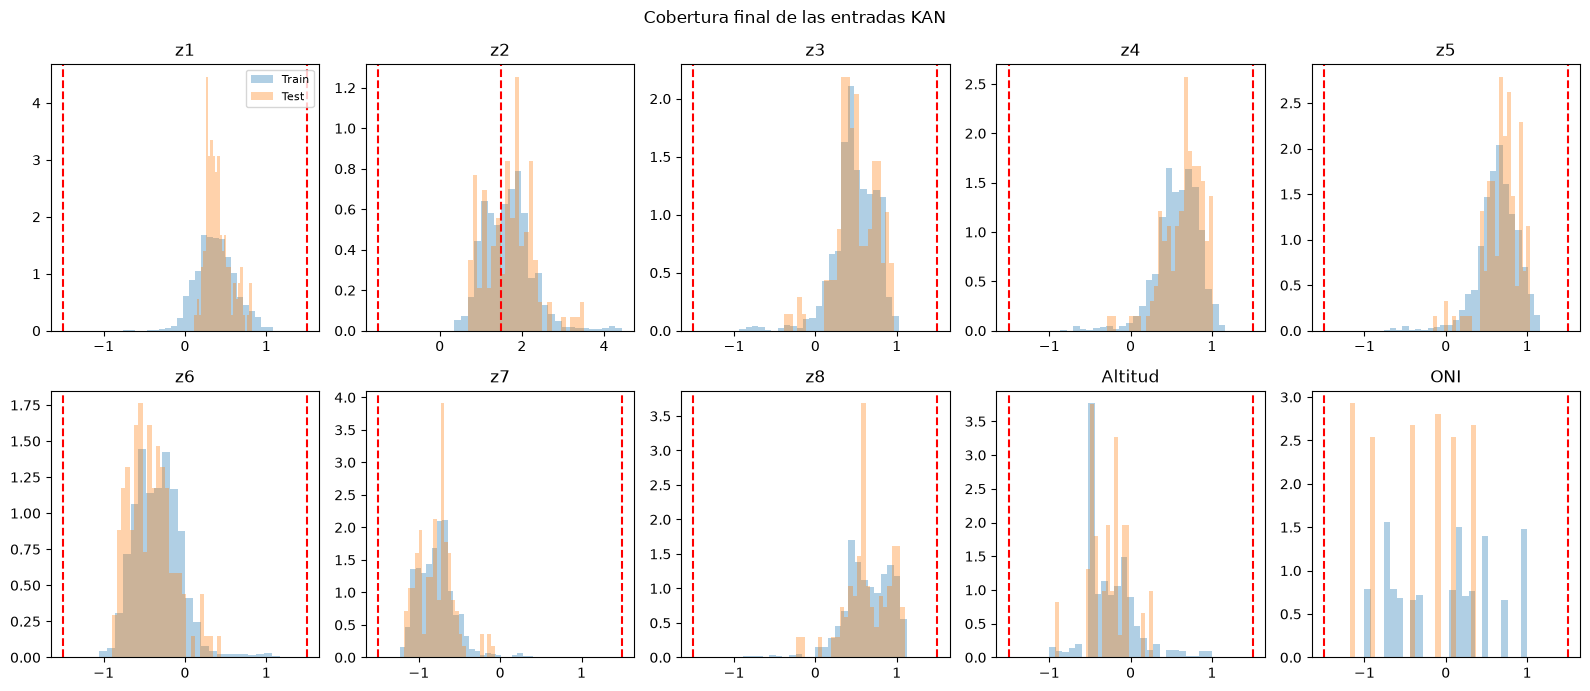

,Entrada,Spline_media_abs,SiLU_media_abs,Spline_casi_cero_pct
0,z1,0.1317,0.0775,0.0000
1,z2,0.0362,0.4960,63.7795
2,z3,0.1208,0.1049,0.0000
3,z4,0.1439,0.1262,0.0000
4,z5,0.1170,0.1345,0.0000
5,z6,0.1866,0.0455,0.0000
6,z7,0.1010,0.0480,0.0000
7,z8,0.1009,0.1274,0.0000
8,Altitud,0.1467,0.0823,0.0000
9,ONI,0.3689,0.0294,0.0000


In [17]:
modelo_diag = modelos[KAN_REF]
ck_diag = estados[KAN_REF]

cov_diag = (datos["cov"] - ck_diag["media_covariables"]) / ck_diag["desviacion_covariables"]

with torch.no_grad():
    entradas_kan = modelo_diag.codificador(
        torch.as_tensor(datos["c_sat"], dtype=torch.float64),
        torch.as_tensor(cov_diag, dtype=torch.float64)
    ).numpy()

capa1 = modelo_diag.cabeza.capas[0]
centros = capa1.centro.detach().numpy()
escalas = capa1.escala.detach().numpy()

z_norm = (entradas_kan - centros) / escalas
labels_z = [f"z{i+1}" for i in range(int(ck_diag["q"]))] + ["Altitud", "ONI"]

soporte_min = float(capa1.nudos[0])
soporte_max = float(capa1.nudos[-1])

filas = []

for j, nombre in enumerate(labels_z):
    fila = {"Entrada": nombre}
    for etiqueta, mascara in [("Train", TRAIN), ("Test", TEST)]:
        valores = z_norm[mascara, j]
        fuera = (valores < soporte_min) | (valores >= soporte_max)
        fila[f"Fuera_soporte_{etiqueta}_pct"] = 100 * fuera.mean()
        fila[f"Media_{etiqueta}"] = valores.mean()
        fila[f"DE_{etiqueta}"] = valores.std()
    filas.append(fila)

tabla_soporte = pd.DataFrame(filas)
display(tabla_soporte.round(3))

print(f"Soporte B-spline: [{soporte_min:.3f}, {soporte_max:.3f})")

fig, axs = plt.subplots(2, 5, figsize=(16, 7))
axs = axs.flatten()

for j, ax in enumerate(axs[:len(labels_z)]):
    for mascara, nombre in [(TRAIN, "Train"), (TEST, "Test")]:
        ax.hist(z_norm[mascara, j], bins=25, density=True, alpha=0.35, label=nombre)
    ax.axvline(soporte_min, color="red", linestyle="--")
    ax.axvline(soporte_max, color="red", linestyle="--")
    ax.set_title(labels_z[j])

for ax in axs[len(labels_z):]:
    ax.axis("off")

axs[0].legend(fontsize=8)
fig.suptitle("Cobertura final de las entradas KAN")
plt.tight_layout()
plt.show()

registros = []

for j, nombre in enumerate(labels_z):
    x = torch.as_tensor(z_norm[TEST, j], dtype=torch.float64)
    with torch.no_grad():
        bases = capa1.bases(x)
        coef = capa1.coeficientes[:, j, :] * capa1.peso_spline[:, j, None]
        aporte_spline = bases @ coef.T
        aporte_silu = torch.nn.functional.silu(x)[:, None] * capa1.peso_base[:, j][None, :]

    registros.append({
        "Entrada": nombre,
        "Spline_media_abs": aporte_spline.abs().mean().item(),
        "SiLU_media_abs": aporte_silu.abs().mean().item(),
        "Spline_casi_cero_pct": (aporte_spline.abs() < 1e-10).double().mean().item() * 100
    })

display(pd.DataFrame(registros).round(4))

## Diagnosticar el aprendizaje de las cinco componentes FPCA

Se compara cada puntaje FPCA predicho con su valor de referencia, obtenido proyectando la curva terrestre en el espacio del decodificador. Se cuantifica la correlación, la desviación estándar, el error y el sesgo de cada componente.

Este análisis permite identificar qué componentes son aprovechadas por la red y cuáles presentan predicciones comprimidas hacia cero o una escasa relación con los valores observados.

,Modelo,Componente,DE_observada,DE_predicha,Ratio_DE,Correlacion,RECM_puntaje,Sesgo_puntaje
0,KAN_s2,1,1.0775,0.9672,0.8977,0.9006,0.4904,-0.1456
1,KAN_s2,2,0.8892,0.5749,0.6466,0.2377,0.9893,-0.3169
2,KAN_s2,3,0.8023,0.6004,0.7483,0.2379,0.8949,-0.1607
3,KAN_s2,4,1.0670,0.5529,0.5182,0.3485,1.0165,0.0162
4,KAN_s2,5,1.1796,0.3265,0.2768,0.1321,1.2263,-0.3279


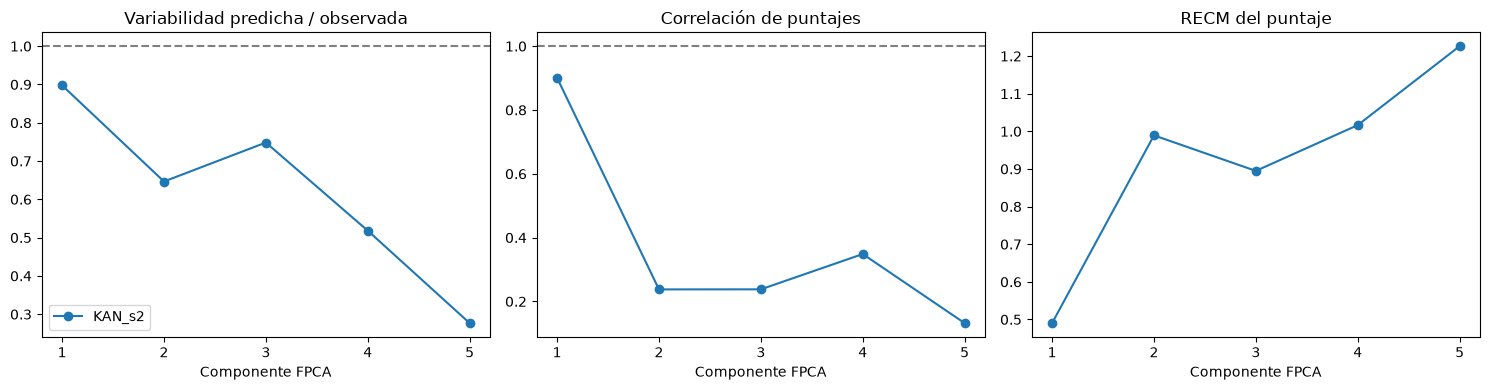

In [18]:
registros_fpca = []

for nombre in [KAN_REF]:
    ck_local = estados[nombre]
    assert np.allclose(ck_local["base_fpca"], ck_diag["base_fpca"]), f"Base FPCA diferente en {nombre}"

    for j in range(int(ck_local["M"])):
        observado = puntajes_obs[TEST, j]
        predicho = scores_pred[nombre][TEST, j]
        de_o = np.std(observado)
        de_p = np.std(predicho)
        correlacion = np.corrcoef(observado, predicho)[0, 1] if de_o > 1e-10 and de_p > 1e-10 else np.nan

        registros_fpca.append({
            "Modelo": nombre,
            "Componente": j + 1,
            "DE_observada": de_o,
            "DE_predicha": de_p,
            "Ratio_DE": de_p / de_o if de_o > 1e-10 else np.nan,
            "Correlacion": correlacion,
            "RECM_puntaje": np.sqrt(np.mean((predicho - observado)**2)),
            "Sesgo_puntaje": np.mean(predicho - observado)
        })

diagnostico_fpca = pd.DataFrame(registros_fpca)
display(diagnostico_fpca.round(4))

fig, axs = plt.subplots(1, 3, figsize=(15, 4))

for nombre, tabla in diagnostico_fpca.groupby("Modelo"):
    axs[0].plot(tabla.Componente, tabla.Ratio_DE, marker="o", label=nombre)
    axs[1].plot(tabla.Componente, tabla.Correlacion, marker="o", label=nombre)
    axs[2].plot(tabla.Componente, tabla.RECM_puntaje, marker="o", label=nombre)

axs[0].axhline(1, color="gray", linestyle="--")
axs[1].axhline(1, color="gray", linestyle="--")

axs[0].set_title("Variabilidad predicha / observada")
axs[1].set_title("Correlación de puntajes")
axs[2].set_title("RECM del puntaje")

for ax in axs:
    ax.set_xlabel("Componente FPCA")
    ax.set_xticks(range(1, int(ck_diag["M"]) + 1))

axs[0].legend()
plt.tight_layout()
plt.show()

## Evaluar si el modelo falla más en eventos de lluvia intensa

Se evalúa el comportamiento de la KAN, el MLP, la cabeza lineal y el satélite en función de la intensidad de la lluvia en la curva de la estación. Los intervalos se construyen utilizando percentiles del conjunto de entrenamiento para evitar seleccionar umbrales a partir de los datos de prueba.

Esta prueba permite identificar si los modelos están reduciendo los errores principalmente en periodos de precipitación baja o moderada, pero subestimando los eventos de mayor intensidad.

,Modelo,Intensidad,N_puntos,Precipitacion_observada_media,Precipitacion_predicha_media,Sesgo_mm,RECM_mm,MAE_mm
0,Satélite,Hasta P50,3463,11.366,16.632,5.266,9.728,7.234
1,Satélite,P50-P75,2354,24.231,26.115,1.883,9.297,7.651
2,Satélite,P75-P90,1960,34.798,29.594,-5.204,11.554,9.413
3,Satélite,P90-P95,623,47.411,31.993,-15.418,18.889,16.207
4,Satélite,Superior P95,744,86.554,42.024,-44.530,51.383,44.883
5,KAN,Hasta P50,3463,11.366,14.230,2.865,7.201,5.613
6,KAN,P50-P75,2354,24.231,22.625,-1.606,8.449,6.699
7,KAN,P75-P90,1960,34.798,28.814,-5.984,11.794,9.584
8,KAN,P90-P95,623,47.411,35.213,-12.198,17.385,14.952
9,KAN,Superior P95,744,86.554,67.117,-19.437,28.540,24.490


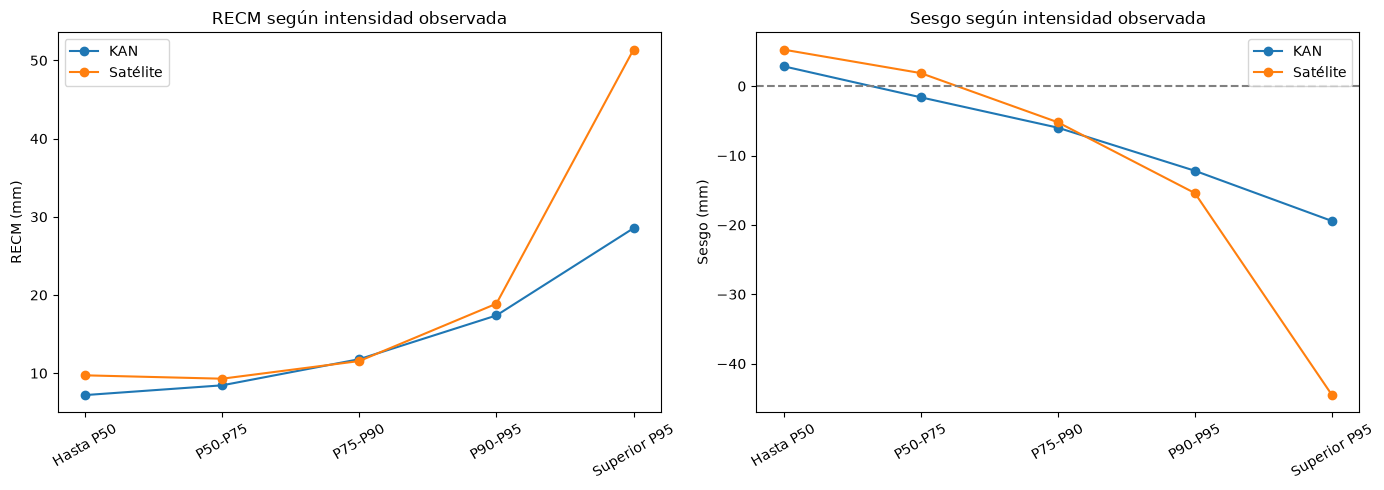

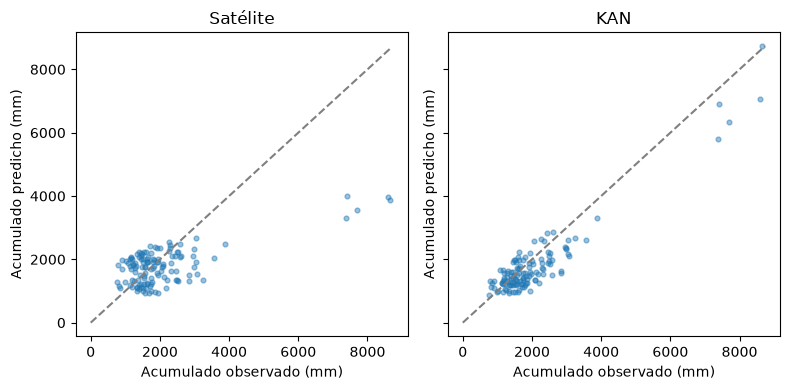

In [19]:
valores_train = Y[TRAIN].ravel()
valores_train = valores_train[np.isfinite(valores_train)]

q50, q75, q90, q95 = np.quantile(valores_train, [0.50, 0.75, 0.90, 0.95])
umbrales = [-np.inf, q50, q75, q90, q95, np.inf]
etiquetas_int = ["Hasta P50", "P50-P75", "P75-P90", "P90-P95", "Superior P95"]

modelos_int = {"Satélite": SAT, "KAN": predicciones[KAN_REF]}
filas_int = []
observado = Y[EVAL]

for nombre, pred in modelos_int.items():
    predicho = pred[EVAL]
    for j, etiqueta in enumerate(etiquetas_int):
        seleccion = (observado > umbrales[j]) & (observado <= umbrales[j+1])
        obs_g = observado[seleccion]
        pred_g = predicho[seleccion]
        if len(obs_g) == 0:
            continue
        diferencia = pred_g - obs_g
        filas_int.append({
            "Modelo": nombre,
            "Intensidad": etiqueta,
            "N_puntos": len(obs_g),
            "Precipitacion_observada_media": obs_g.mean(),
            "Precipitacion_predicha_media": pred_g.mean(),
            "Sesgo_mm": diferencia.mean(),
            "RECM_mm": np.sqrt(np.mean(diferencia**2)),
            "MAE_mm": np.mean(np.abs(diferencia))
        })

tabla_intensidad = pd.DataFrame(filas_int)
display(tabla_intensidad.round(3))

fig, axs = plt.subplots(1, 2, figsize=(14, 5))

for nombre, grupo in tabla_intensidad.groupby("Modelo"):
    grupo = grupo.set_index("Intensidad").reindex(etiquetas_int)
    axs[0].plot(etiquetas_int, grupo["RECM_mm"], marker="o", label=nombre)
    axs[1].plot(etiquetas_int, grupo["Sesgo_mm"], marker="o", label=nombre)

axs[0].set_title("RECM según intensidad observada")
axs[0].set_ylabel("RECM (mm)")
axs[1].set_title("Sesgo según intensidad observada")
axs[1].set_ylabel("Sesgo (mm)")
axs[1].axhline(0, color="gray", linestyle="--")

for ax in axs:
    ax.tick_params(axis="x", rotation=30)
    ax.legend()

plt.tight_layout()
plt.show()

fig, axs = plt.subplots(1, len(modelos_int), figsize=(4*len(modelos_int), 4), sharex=True, sharey=True)

for ax, (nombre, pred) in zip(np.atleast_1d(axs), modelos_int.items()):
    obs_acum = Y[EVAL].sum(axis=1)
    pred_acum = pred[EVAL].sum(axis=1)
    ax.scatter(obs_acum, pred_acum, s=12, alpha=0.45)
    limite = max(obs_acum.max(), pred_acum.max())
    ax.plot([0, limite], [0, limite], linestyle="--", color="gray")
    ax.set_title(nombre)
    ax.set_xlabel("Acumulado observado (mm)")
    ax.set_ylabel("Acumulado predicho (mm)")

plt.tight_layout()
plt.show()

## Peores casos de la KAN seleccionada

Se analizan las seis curvas de prueba con mayor L² relativo, junto con altitud, KGE, sesgo anual y error de ambos picos. La interpretación debe contrastar los eventos intensos, los desfases y el régimen bimodal sin atribuir automáticamente causalidad a ENSO u orografía.

,curva,STATION_ID,YEAR,altitud,L2_relativo,KGE,sesgo_anual_pct,error_Pico_1_MarJun_dias,error_Pico_2_SepDic_dias
0,2624600103_2001,2624600103,2001,951,0.858,0.043,69.507,0,10
1,2624700109_2001,2624700109,2001,1357,0.747,-0.007,52.855,40,15
2,2610000116_2000,2610000116,2000,951,0.713,-0.187,47.819,0,45
3,2612000111_1999,2612000111,1999,1059,0.680,0.130,24.723,50,40
4,2624000102_2001,2624000102,2001,1000,0.639,0.323,44.892,5,20
5,2614200101_2000,2614200101,2000,1560,0.534,-0.018,-44.409,10,0


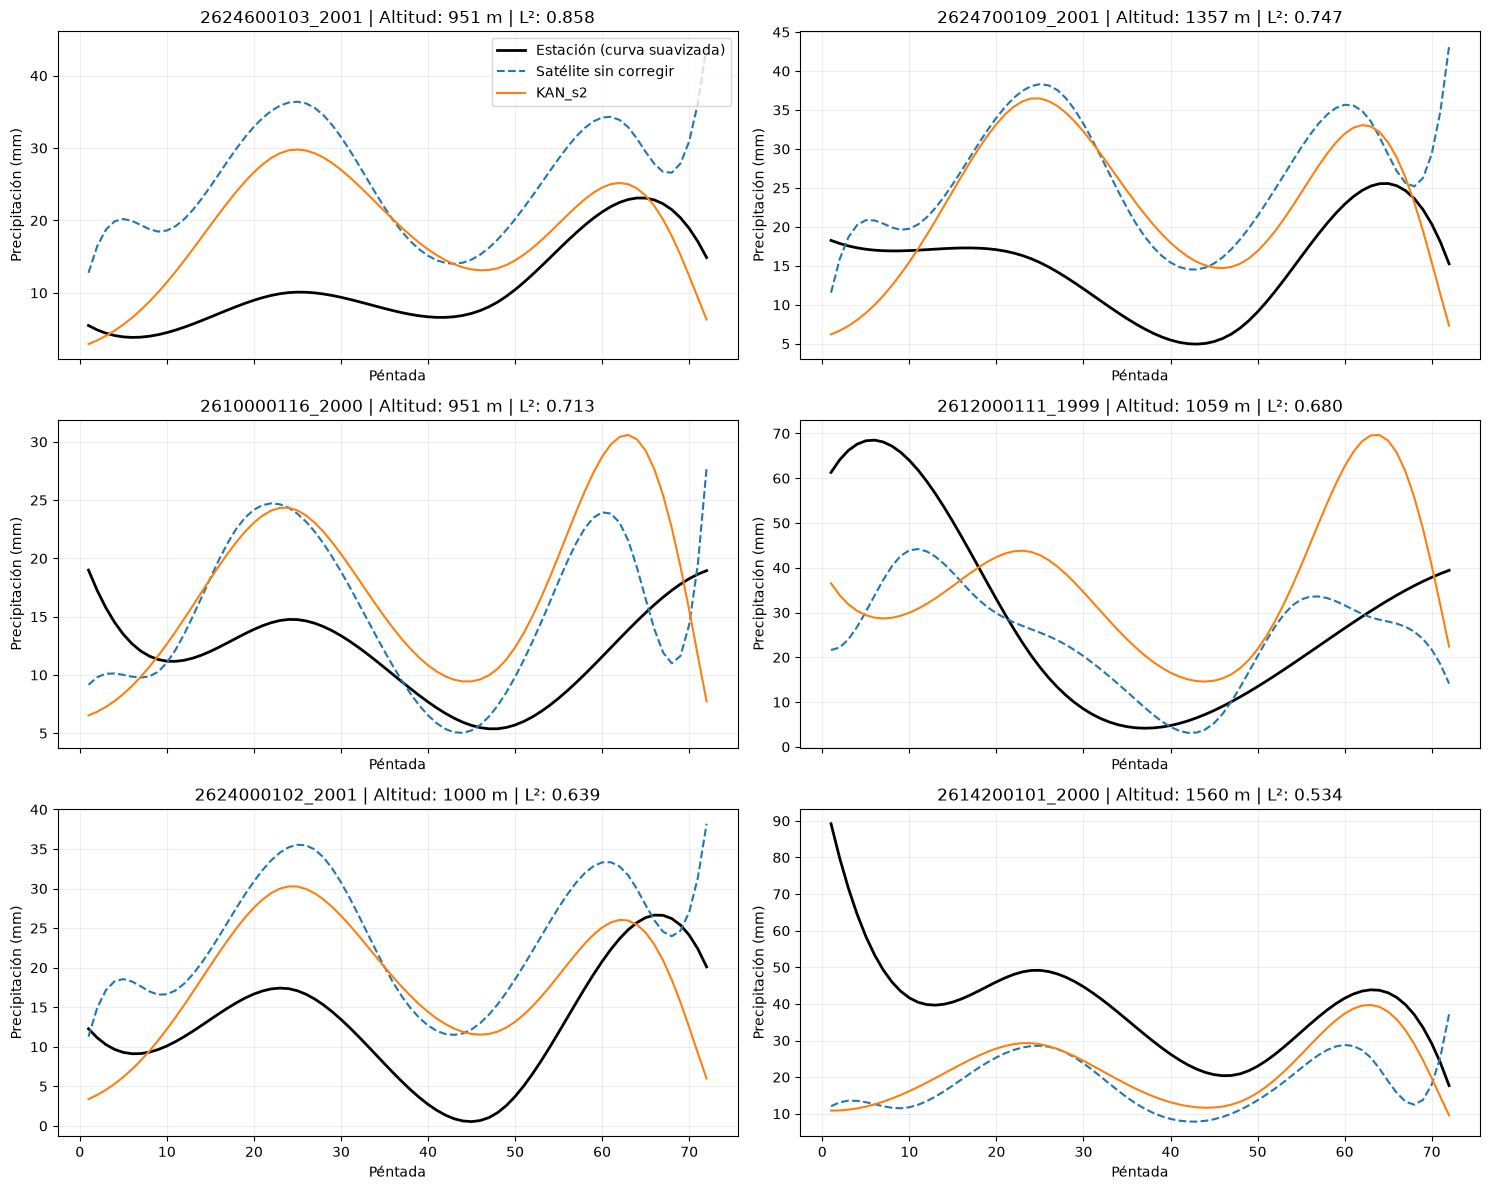

In [20]:
peores = metricas[KAN_REF].sort_values('L2_relativo',ascending=False).head(6).copy()
# Altitud usada por el modelo (catálogo o, si falta, modelo digital de elevación)
geo = meta[['curva','altitud_completa','latitud','longitud']].rename(columns={'altitud_completa': 'altitud'})
peores = peores.merge(geo,on='curva',how='left')
columnas_mostrar = ['curva','STATION_ID','YEAR','altitud','L2_relativo','KGE',
                    'sesgo_anual_pct','error_Pico_1_MarJun_dias','error_Pico_2_SepDic_dias']
display(peores[columnas_mostrar].round(3))
fig,axs=plt.subplots(3,2,figsize=(15,12),sharex=True)
for ax,fila in zip(axs.flat,peores.itertuples()):
    i=int(np.flatnonzero(ids==fila.curva)[0])
    ax.plot(P,Y[i],label='Estación (curva suavizada)',color='black',linewidth=2)
    ax.plot(P,SAT[i],label='Satélite sin corregir',linestyle='--')
    ax.plot(P,predicciones[KAN_REF][i],label=KAN_REF)
    ax.set_title(f'{fila.curva} | Altitud: {fila.altitud:.0f} m | L²: {fila.L2_relativo:.3f}')
    ax.set(xlabel='Péntada',ylabel='Precipitación (mm)');ax.grid(alpha=.2)
axs[0,0].legend();plt.tight_layout()
plt.show()

## Predicciones de las estaciones reservadas 

In [21]:
est_train = set(meta.loc[TRAIN, "STATION_ID"].astype(str))
est_test = set(meta.loc[TEST, "STATION_ID"].astype(str))

est_reservadas = est_test - est_train

print("Estaciones exclusivas de prueba:", len(est_reservadas))
print("Identificadores:", sorted(est_reservadas))

assert len(est_reservadas) > 0, "No se encontraron estaciones exclusivas de prueba."

mask_reservadas = TEST & meta["STATION_ID"].astype(str).isin(est_reservadas).to_numpy()
indices = np.flatnonzero(mask_reservadas)

pred_kan = predicciones[KAN_REF]

assert pred_kan.shape[0] == len(meta)
assert pred_kan.shape[1] == 72
assert np.isfinite(pred_kan[indices]).all()

# Día del año en que empieza cada péntada (días 1, 6, 11, 16, 21 y 26 de cada mes); value_mm es el total de la péntada
def dias_inicio(year):
    return [pd.Timestamp(year, mes, dia).day_of_year for mes in range(1, 13) for dia in (1, 6, 11, 16, 21, 26)]

registros = []

for i in indices:
    station_id = str(meta.iloc[i]["STATION_ID"])
    year = int(meta.iloc[i]["YEAR"])
    for day, value in zip(dias_inicio(year), pred_kan[i]):
        registros.append({"station_id": station_id, "year": year, "day": int(day), "value_mm": float(value)})

predicciones_reservadas = pd.DataFrame(registros, columns=["station_id", "year", "day", "value_mm"])

assert not predicciones_reservadas.empty
assert set(predicciones_reservadas["station_id"]).isdisjoint(est_train)
assert predicciones_reservadas["year"].between(1998, 2003).all()
assert predicciones_reservadas["value_mm"].ge(0).all()
assert len(predicciones_reservadas) == len(indices) * 72

ruta_csv = OUT / "predicciones_estaciones_reservadas.csv"
predicciones_reservadas.to_csv(ruta_csv, index=False)

print("\nEXPORTACIÓN COMPLETADA")
print("Modelo:", KAN_REF)
print("Estaciones:", len(est_reservadas))
print("Curvas estación-año:", len(indices))
print("Predicciones exportadas:", len(predicciones_reservadas))
print("Archivo:", ruta_csv)

display(predicciones_reservadas.head(10))

Estaciones exclusivas de prueba: 26
Identificadores: ['2610000115', '2610000116', '2612000111', '2612810108', '2612810109', '2612810112', '2613100103', '2613600102', '2614200101', '2614400104', '2614900101', '2615000101', '2615400102', '2620000105', '2622100103', '2622330102', '2622330105', '2622330106', '2622900102', '2624000101', '2624000102', '2624600101', '2624600103', '2624700109', '2625500102', '5301500108']

EXPORTACIÓN COMPLETADA
Modelo: KAN_s2
Estaciones: 26
Curvas estación-año: 127
Predicciones exportadas: 9144
Archivo: /Users/estefania/Documents/GitHub/proyecto_final_analiticaDeDatos/predicciones_estaciones_reservadas.csv


,station_id,year,day,value_mm
0,2610000115,1998,1,4.359195
1,2610000115,1998,6,4.830103
2,2610000115,1998,11,5.377177
3,2610000115,1998,16,6.001770
4,2610000115,1998,21,6.704414
5,2610000115,1998,26,7.484574
6,2610000115,1998,32,8.340422
7,2610000115,1998,37,9.268669
8,2610000115,1998,42,10.264420
9,2610000115,1998,47,11.321077


## Interpretación climatológica de los resultados

### Régimen bimodal
La KAN_s2 reproduce el patrón general de dos temporadas lluviosas, coherente con las funciones de peso $w_k(t)$, que presentan variaciones importantes en ambas ventanas del año. Sus predicciones son más suaves que la curva de la estación y no capturan los picos abruptos. El error temporal promedio de los dos picos fue de **14.67 días**, frente a **22.95 días** del satélite (diferencia de −8.29 días, IC 95 % de −9.65 a −6.90). La mejora está en el segundo pico (9.29 frente a 29.37 días; diferencia −20.08, IC 95 % de −22.59 a −17.66); en el primero la KAN empeora (20.04 frente a 16.54 días; diferencia +3.50, IC 95 % de 1.34 a 5.55).

### Orografía
Las activaciones asociadas con la altitud muestran relaciones no lineales y cambios de signo, lo que evidencia que la KAN transforma esta covariable. Los peores casos se presentan en estaciones entre **951 y 1560 m** (dos de ellas con la altitud tomada del modelo digital de elevación), por lo que no puede atribuirse el error únicamente a la elevación. La estación 2624600103 (951 m) presentó el mayor error L² relativo (**0.858**) en 2001, con una sobreestimación del acumulado de +69.5 %; cinco de los seis peores casos sobreestiman la lluvia y todos son de 1999 a 2001.

### ENSO
El modelo presentó un RECM menor que el satélite en las tres fases: **La Niña** (12.01 frente a 15.45 mm), **El Niño** (9.13 frente a 10.66 mm) y Neutral (7.77 frente a 10.88 mm). En Neutral la KAN corrige la sobreestimación del satélite (de +11.9 % a −4.8 %) y en El Niño la reduce poco (de +15.4 % a +12.8 %); durante La Niña ambas fuentes subestiman de forma parecida (−8.8 % la KAN y −7.3 % el satélite). Estos resultados son descriptivos y se basan en 86, 63 y 104 segmentos clasificados como La Niña, El Niño y Neutral, respectivamente, utilizando el ONI de NOAA.

### KAN frente a la cabeza lineal, la MLP y el satélite
La KAN obtuvo un **L² relativo de 0.363**, menor que el satélite (0.445) y que la cabeza lineal (0.393); frente al satélite la diferencia es −0.082 (IC 95 % de −0.135 a −0.036). Su KGE fue **0.493**, frente a 0.401 del satélite (diferencia +0.093, IC 95 % de 0.027 a 0.161). Su sesgo anual es de **−6.61 %**, frente a +2.33 % del satélite; el IC 95 % de la diferencia incluye el cero (−19.26 a 0.93). El RECM baja de 13.94 a 10.95 mm, el menor de los cuatro modelos.

La MLP también supera al satélite en L² relativo (0.356; diferencia −0.090, IC 95 % de −0.145 a −0.042) y KGE (0.510; diferencia +0.109, IC 95 % de 0.043 a 0.174), pero subestima más el acumulado anual (−9.49 %; diferencia −11.82 puntos, IC 95 % de −23.08 a −1.25).

Las activaciones de la capa muestran relaciones no lineales que no aparecen en los coeficientes fijos de la cabeza lineal. El ajuste simbólico de la arista de mayor variabilidad (ONI → c2) obtuvo un **R² de 0.44** en puntos no usados en el ajuste, de modo que un polinomio cúbico no la describe bien.

### Limitaciones y peores casos
La KAN suaviza la precipitación y pierde variabilidad. Subestima los eventos intensos, aunque menos que el satélite: por encima del percentil 95 de entrenamiento su sesgo es de −19.4 mm, frente a −44.5 mm del satélite. El análisis FPCA mostró que la primera componente se aprende bien (correlación de 0.90 entre el puntaje predicho y el de referencia); en las componentes 2 a 5 la correlación está entre 0.13 y 0.35 y la desviación predicha es el 65 %, 75 %, 52 % y 28 % de la de referencia. La reconstrucción con los puntajes reales (oráculo) tiene un RECM de 3.46 mm frente a 10.95 mm de la KAN, así que el error viene de la cabeza y no del decodificador. Además, la entrada **z2 se encuentra fuera del soporte de las B-splines en el 59 % de las curvas de entrenamiento y el 64 % de las de prueba**, de modo que su contribución spline es casi nula.

Se evaluaron las 127 curvas de prueba (1998–2003). Las 26 estaciones de prueba son independientes de las utilizadas en entrenamiento y no comparten píxel satelital con ellas, y las reglas del preprocesamiento se revisaron solo con las estaciones de entrenamiento.

### Conclusión
La KAN_s2, sin capa oculta, aprende patrones no lineales y reproduce la estructura bimodal general de la precipitación, pero presenta dificultades para capturar eventos intensos y variaciones locales. En prueba **mejora al satélite en L² relativo, KGE y el error de la fecha de los dos picos**, con intervalos que excluyen el cero, y tiene el menor RECM; en el sesgo anual no se distingue del satélite. La MLP mejora en L² relativo y KGE de forma parecida, pero con más sesgo. En validación cruzada (`03_Ablacion_cabezas.ipynb`) la KAN supera a la MLP en L² relativo y KGE, sin diferencia en RECM ni en sesgo, y ambas superan al satélite en L² relativo, KGE y RECM.